In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
import umap

LATENTS = 8
MODEL = 3 # 1: GRU, 2: TRANSFORMER, 3: MOTION_PREDICTION
COLUMN = 3 # 0: Object type, 1: Direction, 2: Acceleration, 3: Speed
TRAIN_SAMPLE = 20000
TEST_SAMPLE = 5000

NOISY = False

model_name = {1: "GRU", 2: "TRANSFORMER", 3: "MOTION_PREDICTION"}

# Folder
embeddings_folder = "../" + model_name[MODEL]

# Embeddings files

train_embeddings_file = embeddings_folder + "/latents_folder/" + "train_latents_" + str(LATENTS) + ".npy"
test_embeddings_file = embeddings_folder + "/latents_folder/" + "test_latents_" + str(LATENTS) + ".npy"

# Labels files
train_labels_file = "../model_arrays/train_array_labels.npy"
test_labels_file = "../model_arrays/test_array_labels.npy"

column_titles = ["Object type Labels", "Direction Labels", "Acceleration Labels", "Speed Labels"]
label_types = [["Vehicle","Pedestrian","Construction","Riderless Bicycle","Bus","Background","Static","Cyclist","Motorcyclist","Unknown"], ["Straight","U Turn","Left Turn","Right Turn","Unspecified"], ["Constant Speed","Decelerate","Accelerate"], ["Speed 4","Speed 3","Speed 2","Speed 1","Speed 0"]]

# Create folder
base_name = os.path.splitext(train_embeddings_file)[0]

folder_name = embeddings_folder + "/visualizations/" + "latents_" + str(LATENTS)

if NOISY and (LATENTS == 8):
    test_embeddings_file = embeddings_folder + "/latents_folder/" + "noisy_test_latents.npy"
    folder_name += "_noisy"

if not os.path.exists(folder_name):
    os.makedirs(folder_name)
    print(f"Δημιουργήθηκε ο καθαρός φάκελος: '{folder_name}/'")

Δημιουργήθηκε ο καθαρός φάκελος: '../MOTION_PREDICTION/visualizations/../MOTION_PREDICTION/latents_folder/latents_8/'


Αρχικό σχήμα Embeddings: (65790, 8)
Αρχικό σχήμα Labels:     (65790, 4)
Εκτέλεση K-Means...
Εκτέλεση Hierarchical Clustering (Ward)...
Εκτέλεση DBSCAN...
Εκτέλεση UMAP...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


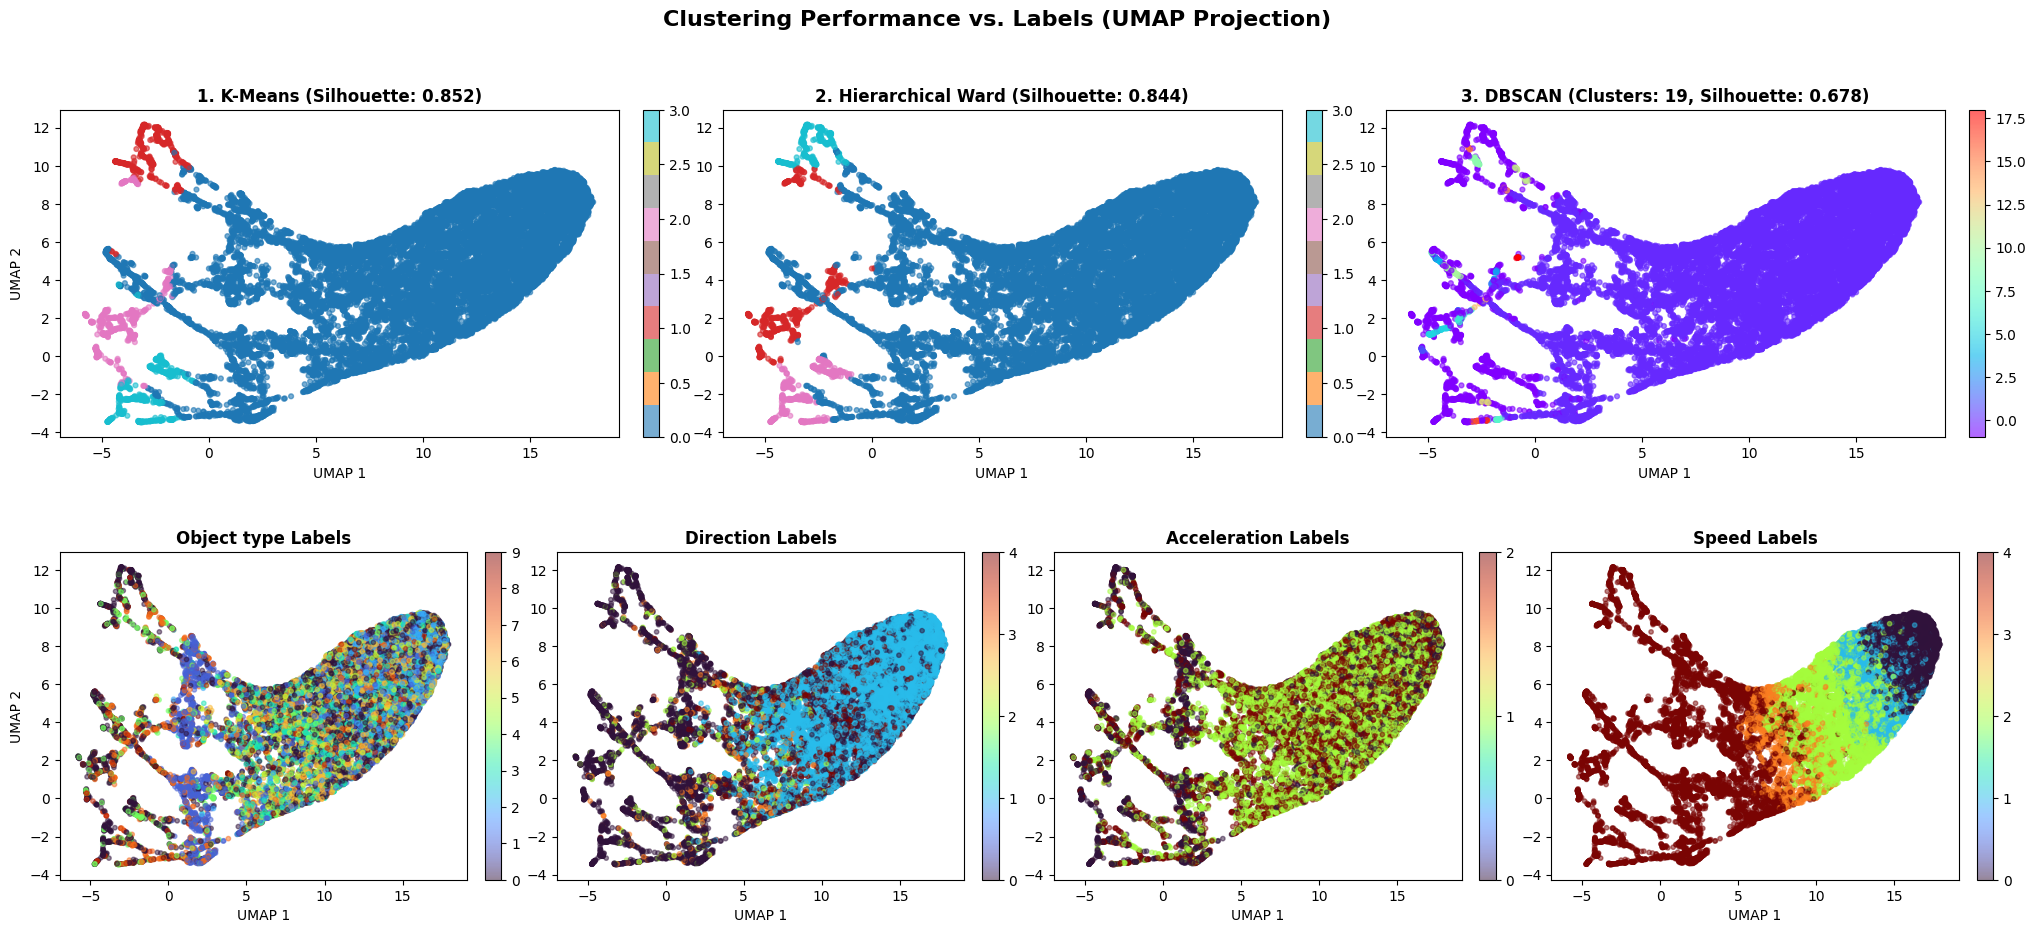


Plot saved as 'clustering_and_labels_umap_train.png'


In [ ]:
#Clustering and Visualization

embeddings_file = train_embeddings_file
labels_file = train_labels_file
SAMPLE_SIZE = TRAIN_SAMPLE

X = np.load(embeddings_file)
labels = np.load(labels_file)

print(f"Αρχικό σχήμα Embeddings: {X.shape}") # (65790, 32)
print(f"Αρχικό σχήμα Labels:     {labels.shape}") # (65790, 4)

np.random.seed(42)
indices = np.random.choice(len(X), size=SAMPLE_SIZE, replace=False)

X_sample = X[indices]
labels_sample = labels[indices]

# Κανονικοποίηση
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

# ============== #
#   CLUSTERING   #
# ============== #
print("Εκτέλεση K-Means...")
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)

print("Εκτέλεση Hierarchical Clustering (Ward)...")
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)
agg_sil = silhouette_score(X_scaled, agg_labels)

print("Εκτέλεση DBSCAN...")
dbscan = DBSCAN(eps=0.5, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)
dbscan_sil = silhouette_score(X_scaled, dbscan_labels)
n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

# ===================== #
#   UNSUPERVISED UMAP   #
# ===================== #
print("Εκτέλεση UMAP...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

# ================= #
#   VISUALISATION   #
# ================= #
fig = plt.figure(figsize=(25, 10))
gs = fig.add_gridspec(2, 12, hspace=0.35, wspace=0.45)
GLOBAL_CMAP = "turbo"

# --- ΣΕΙΡΑ 1: ΑΛΓΟΡΙΘΜΟΙ ΟΜΑΔΟΠΟΙΗΣΗΣ (Clustering) ---
# Panel 1: K-Means
ax_km = fig.add_subplot(gs[0, 0:4])
scatter_km = ax_km.scatter(X_umap[:, 0], X_umap[:, 1], c=kmeans_labels, s=12, cmap="tab10", alpha=0.6)
ax_km.set_title(f"1. K-Means (Silhouette: {kmeans_sil:.3f})", fontsize=12, fontweight='bold')
ax_km.set_xlabel("UMAP 1")
ax_km.set_ylabel("UMAP 2")
fig.colorbar(scatter_km, ax=ax_km, fraction=0.046, pad=0.04)

# Panel 2: Hierarchical
ax_agg = fig.add_subplot(gs[0, 4:8])
scatter_agg = ax_agg.scatter(X_umap[:, 0], X_umap[:, 1], c=agg_labels, s=12, cmap="tab10", alpha=0.6)
ax_agg.set_title(f"2. Hierarchical Ward (Silhouette: {agg_sil:.3f})", fontsize=12, fontweight='bold')
ax_agg.set_xlabel("UMAP 1")
fig.colorbar(scatter_agg, ax=ax_agg, fraction=0.046, pad=0.04)

# Panel 3: DBSCAN
ax_db = fig.add_subplot(gs[0, 8:12])
scatter_db = ax_db.scatter(X_umap[:, 0], X_umap[:, 1], c=dbscan_labels, s=12, cmap="rainbow", alpha=0.6)
ax_db.set_title(f"3. DBSCAN (Clusters: {n_clusters_db}, Silhouette: {dbscan_sil:.3f})", fontsize=12, fontweight='bold')
ax_db.set_xlabel("UMAP 1")
fig.colorbar(scatter_db, ax=ax_db, fraction=0.046, pad=0.04)


# --- ΣΕΙΡΑ 2: LABELS ---
for col_idx in range(4):
    col_start = col_idx * 3
    col_end = col_start + 3
    ax_label = fig.add_subplot(gs[1, col_start:col_end])

    clean_column = labels_sample[:, col_idx].astype(int)
    unique_cats = np.unique(clean_column)

    scatter_lbl = ax_label.scatter(X_umap[:, 0], X_umap[:, 1], c=clean_column, s=10, cmap=GLOBAL_CMAP, alpha=0.5)
    ax_label.set_title(column_titles[col_idx], fontsize=12, fontweight='bold')
    ax_label.set_xlabel("UMAP 1")
    if col_idx == 0:
        ax_label.set_ylabel("UMAP 2")

    cbar = fig.colorbar(scatter_lbl, ax=ax_label, ticks=unique_cats, fraction=0.046, pad=0.04)
    cbar.ax.set_yticklabels([str(cat) for cat in unique_cats])

plt.suptitle("Clustering Performance vs. Labels (UMAP Projection)", fontsize=16, y=0.98, fontweight='bold')

# Αποθήκευση εικόνας
output_filename = "clustering_and_labels_umap_train.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nPlot saved as '{output_filename}'")

Απομονώθηκαν 5 διαφορετικά label types για το Speed Labels: [0 1 2 3 4]
Εκτέλεση UMAP...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\strat\AppData\Local\Temp\ipykernel_38188\2535838713.py:43: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("turbo", n_labels)


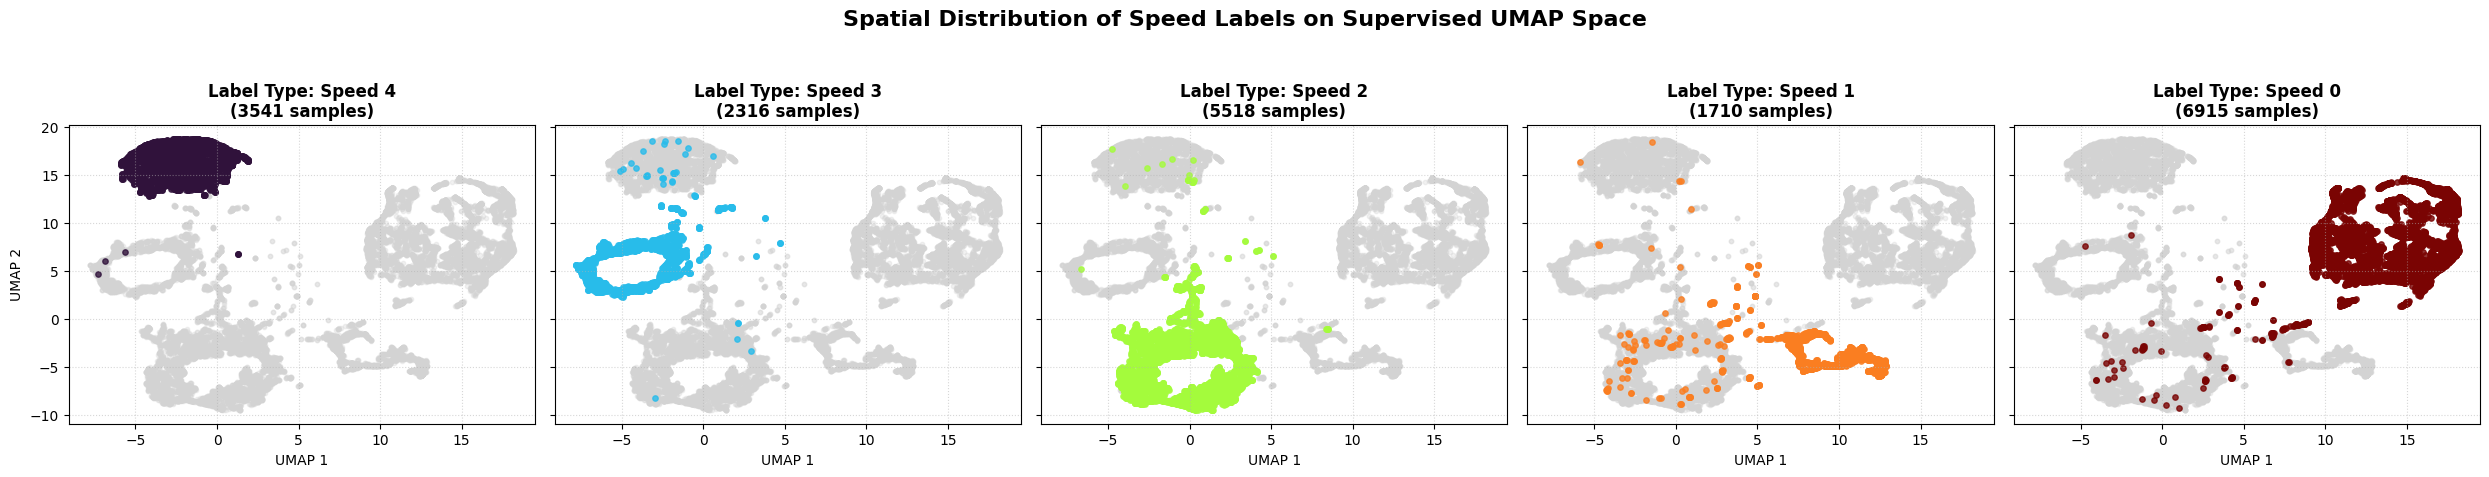


Plot saved as 'train_umap_column_3_labels_separately_SUPERVISED.png'


In [ ]:
#Separate Plots for Column Labels
embeddings_file = train_embeddings_file
labels_file = train_labels_file

# print(f"Πραγματικό μέγεθος X: {X.shape}")
# print(f"Πραγματικό μέγεθος labels: {labels.shape}")

X = np.load(embeddings_file)
labels = np.load(labels_file)

SAMPLE_SIZE = TRAIN_SAMPLE
np.random.seed(42)
indices = np.random.choice(len(X), size=SAMPLE_SIZE, replace=False)

X_sample = X[indices]
ground_truth_col3 = labels[indices][:, COLUMN].astype(int)

unique_labels = np.sort(np.unique(ground_truth_col3))
n_labels = len(unique_labels)

print(f"Απομονώθηκαν {n_labels} διαφορετικά label types για το {column_titles[COLUMN]}: {unique_labels}")

# Κανονικοποίηση και UMAP
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

print("Εκτέλεση UMAP...")

labels_sample = labels[indices]
clean_column = labels_sample[:, COLUMN].astype(int)

reducer = umap.UMAP(n_neighbors=40, min_dist=0.1, random_state=60)
X_umap = reducer.fit_transform(X_scaled, y=clean_column)

# ================= #
#   VISUALISATION   #
# ================= #
fig, axes = plt.subplots(1, n_labels, figsize=(5 * n_labels, 4.5), sharex=True, sharey=True)

if n_labels == 1:
    axes = [axes]

colors = plt.cm.get_cmap("turbo", n_labels)

for idx, label_val in enumerate(unique_labels):
    ax = axes[idx]

    ax.scatter(X_umap[:, 0], X_umap[:, 1], c="lightgrey", s=10, alpha=0.3, label="Other labels")

    mask = (ground_truth_col3 == label_val)

    ax.scatter(X_umap[mask, 0], X_umap[mask, 1], c=[colors(idx)], s=15, alpha=0.8, label=f"Val {label_val}")

    ax.set_title(f"Label Type: {label_types[COLUMN][label_val]}\n({np.sum(mask)} samples)", fontsize=12, fontweight='bold')
    ax.set_xlabel("UMAP 1")
    if idx == 0:
        ax.set_ylabel("UMAP 2")
    ax.grid(True, linestyle=":", alpha=0.5)

plt.suptitle(f"Spatial Distribution of {column_titles[COLUMN]} on Supervised UMAP Space", fontsize=16, y=1.05, fontweight='bold')
plt.tight_layout()

# Αποθήκευση εικόνας
output_filename = f"train_umap_column_{COLUMN}_labels_separately_SUPERVISED.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nPlot saved as '{output_filename}'")

Train Latents Shape: (58713, 4) | Labels: (65790,)
Test Latents Shape:  (6524, 4) | Labels: (7311,)

Supervised UMAP στα Train data (με labels)...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Plotting Test data on UMAP space without labels...


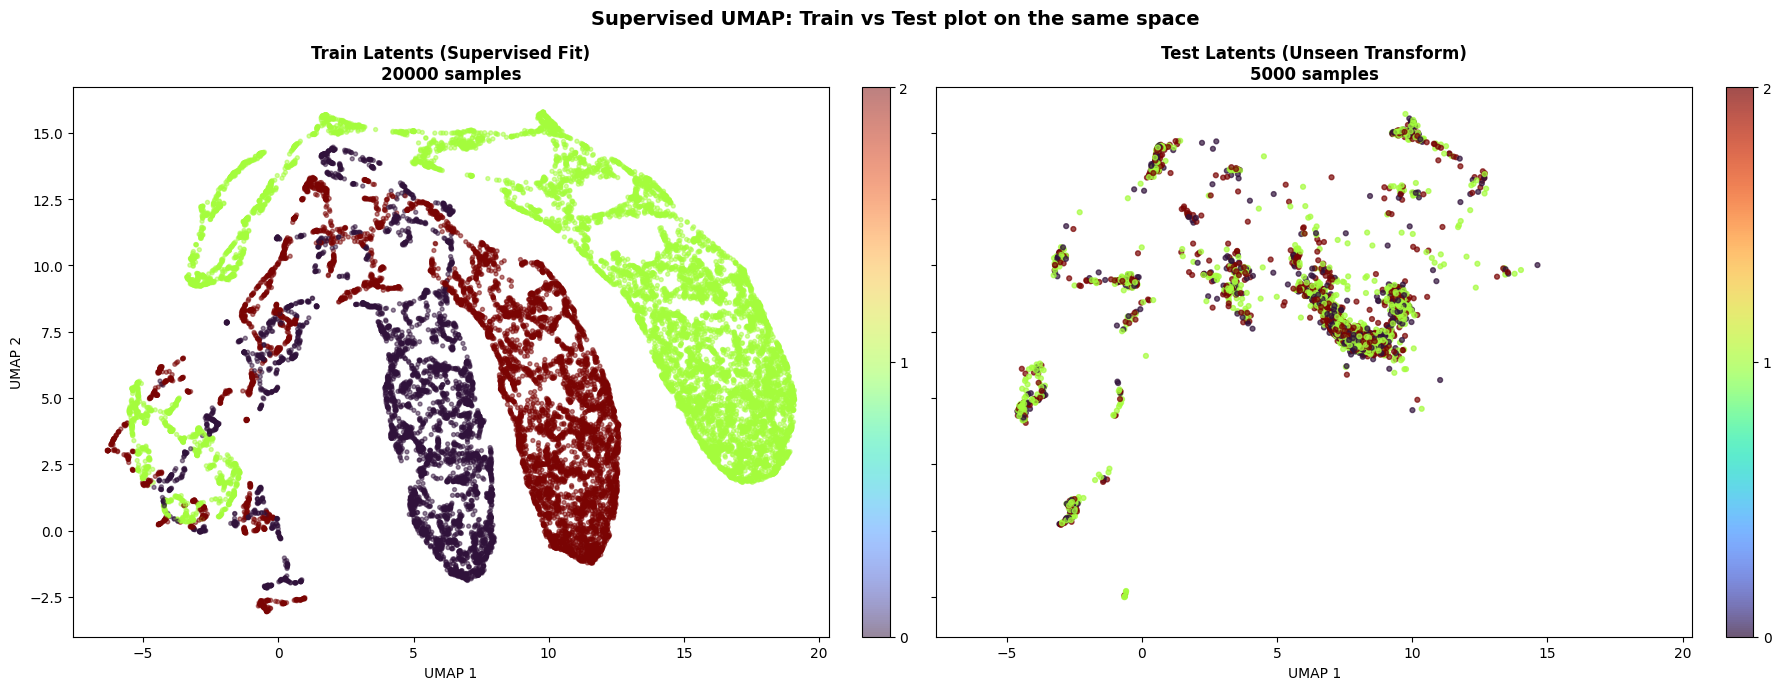


Plot saved as 'umap_train_vs_test_SUPERVISED.png'


In [ ]:
# Train vs Test on the same UMAP space (Supervised)
X_train_raw = np.load(train_embeddings_file)
y_train_raw = np.load(train_labels_file)[:, COLUMN].astype(int) # Column n για Train

X_test_raw = np.load(test_embeddings_file)
y_test_raw = np.load(test_labels_file)[:, COLUMN].astype(int)   # Column n για Test

print(f"Train Latents Shape: {X_train_raw.shape} | Labels: {y_train_raw.shape}")
print(f"Test Latents Shape:  {X_test_raw.shape} | Labels: {y_test_raw.shape}")

np.random.seed(42)
train_idx = np.random.choice(len(X_train_raw), size=min(TRAIN_SAMPLE, len(X_train_raw)), replace=False)
test_idx = np.random.choice(len(X_test_raw), size=min(TEST_SAMPLE, len(X_test_raw)), replace=False)

X_train = X_train_raw[train_idx]
y_train = y_train_raw[train_idx]

X_test = X_test_raw[test_idx]
y_test = y_test_raw[test_idx]

# Κανονικοποίηση
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =================== #
#   SUPERVISED UMAP   #
# =================== #
print("\nSupervised UMAP στα Train data...")
reducer = umap.UMAP(n_neighbors=40, min_dist=0.1, random_state=60)

X_umap_train = reducer.fit_transform(X_train_scaled, y=y_train)

print("Plotting Test data on UMAP space without labels...")
X_umap_test = reducer.transform(X_test_scaled)

# ================= #
#   VISUALISATION   #
# ================= #
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), sharex=True, sharey=True)
GLOBAL_CMAP = "turbo"

# Αριστερό Panel: Train
scatter1 = ax1.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c=y_train, s=8, cmap=GLOBAL_CMAP, alpha=0.5)
ax1.set_title(f"Train Latents (Supervised Fit)\n{len(X_train)} samples", fontsize=12, fontweight='bold')
ax1.set_xlabel("UMAP 1")
ax1.set_ylabel("UMAP 2")
fig.colorbar(scatter1, ax=ax1, ticks=np.unique(y_train), fraction=0.046, pad=0.04)

# Δεξί Panel: Test
scatter2 = ax2.scatter(X_umap_test[:, 0], X_umap_test[:, 1], c=y_test, s=12, cmap=GLOBAL_CMAP, alpha=0.7)
ax2.set_title(f"Test Latents (Unseen Transform)\n{len(X_test)} samples", fontsize=12, fontweight='bold')
ax2.set_xlabel("UMAP 1")
fig.colorbar(scatter2, ax=ax2, ticks=np.unique(y_test), fraction=0.046, pad=0.04)

plt.suptitle("Supervised UMAP: Train vs Test plot on the same space", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

output_filename = "umap_train_vs_test_SUPERVISED.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nPlot saved as '{output_filename}'")

Train Latents Shape: (65790, 16) | Labels: (65790,)
Test Latents Shape:  (7311, 16) | Labels: (7311,)

Unsupervised UMAP στα Train data (χωρίς ground truth labels)...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Προβολή (Transform) των Test data στον Unsupervised χώρο...


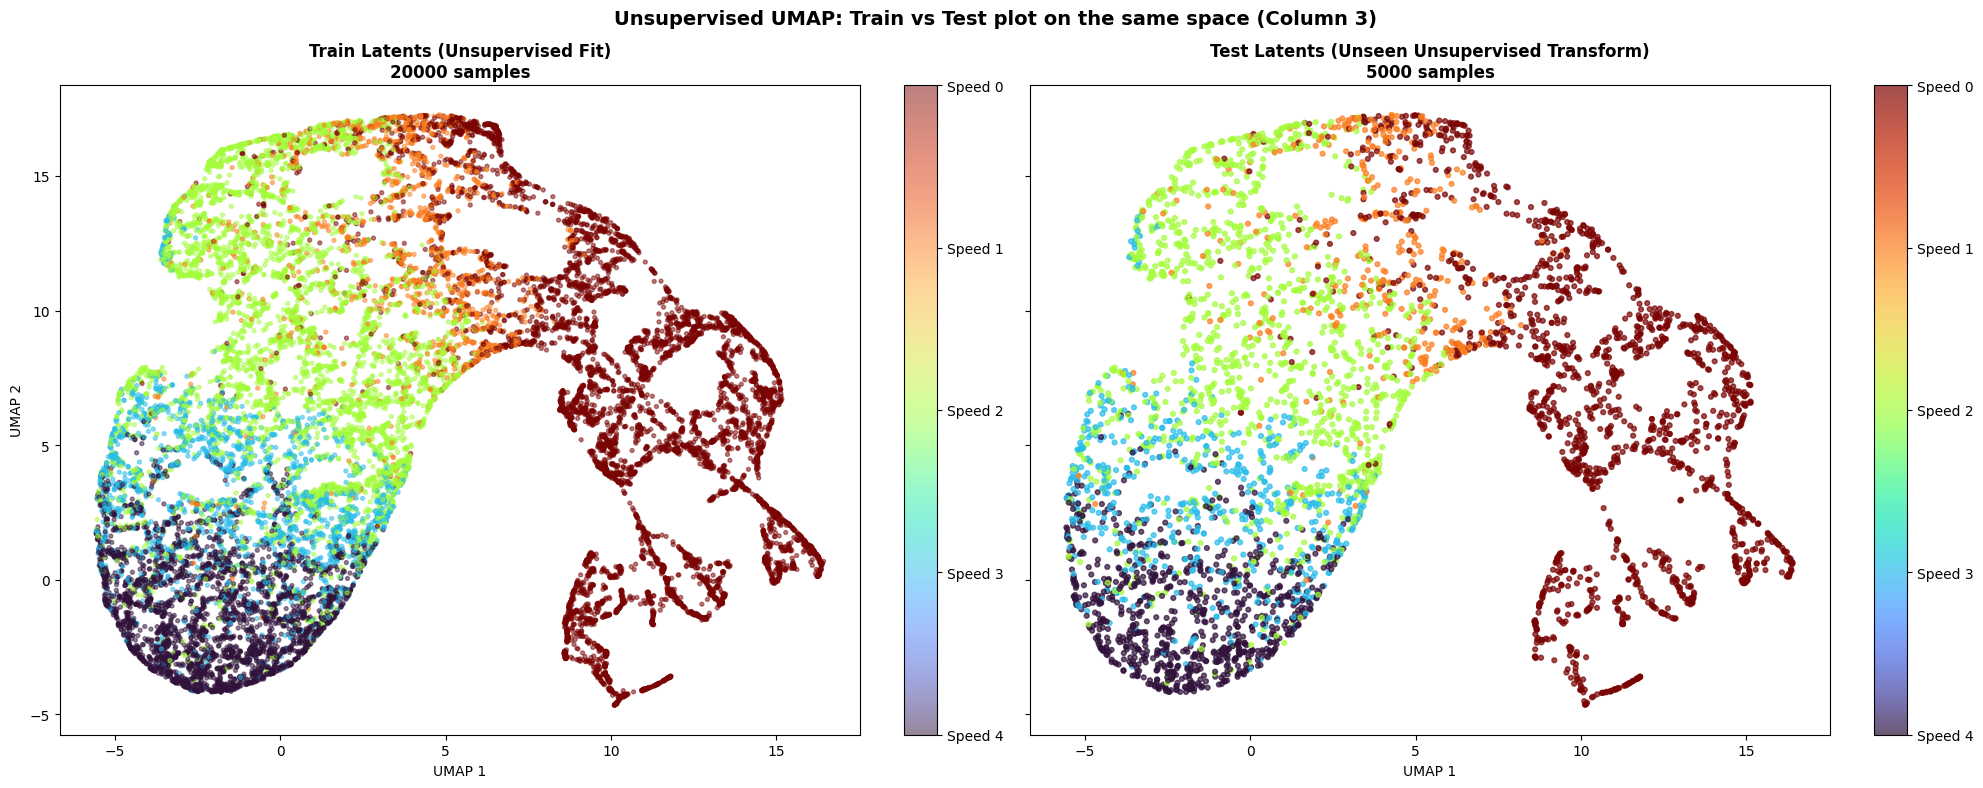


Plot saved as 'umap_train_vs_test_UNSUPERVISED.png'


In [ ]:
# Unsupervised UMAP: Train vs Test on the same UMAP space
X_train_raw = np.load(train_embeddings_file)
y_train_raw = np.load(train_labels_file)[:, COLUMN].astype(int) # Column n για Train

X_test_raw = np.load(test_embeddings_file)
y_test_raw = np.load(test_labels_file)[:, COLUMN].astype(int)   # Column n για Test

print(f"Train Latents Shape: {X_train_raw.shape} | Labels: {y_train_raw.shape}")
print(f"Test Latents Shape:  {X_test_raw.shape} | Labels: {y_test_raw.shape}")

np.random.seed(42)
train_idx = np.random.choice(len(X_train_raw), size=min(TRAIN_SAMPLE, len(X_train_raw)), replace=False)
test_idx = np.random.choice(len(X_test_raw), size=min(TEST_SAMPLE, len(X_test_raw)), replace=False)

X_train = X_train_raw[train_idx]
y_train = y_train_raw[train_idx]

X_test = X_test_raw[test_idx]
y_test = y_test_raw[test_idx]

# Κανονικοποίηση
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ===================== #
#   UNSUPERVISED UMAP   #
# ===================== #
print("\nUnsupervised UMAP στα Train data (χωρίς ground truth labels)...")
reducer = umap.UMAP(n_neighbors=40, min_dist=0.1, random_state=60)

# ΚΡΙΣΙΜΟ: Αφαιρέσαμε το y=y_train. Τώρα το UMAP μαθαίνει τυφλά!
X_umap_train = reducer.fit_transform(X_train_scaled)

print("Προβολή (Transform) των Test data στον Unsupervised χώρο...")
X_umap_test = reducer.transform(X_test_scaled)

# ================= #
#   VISUALISATION   #
# ================= #
# Χρησιμοποιούμε τη λίστα TEXT_LABELS που φτιάξαμε πριν για καθαρά strings στο Colorbar
TEXT_LABELS = [
    ["Vehicle", "Pedestrian", "Construction", "Riderless Bicycle", "Bus", "Background", "Static", "Cyclist", "Motorcyclist", "Unknown"],
    ["Straight", "U Turn", "Left Turn", "Right Turn", "Unspecified"],
    ["Constant Speed", "Decelerate", "Accelerate"],
    ["Speed 4", "Speed 3", "Speed 2", "Speed 1", "Speed 0"]
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), sharex=True, sharey=True)
GLOBAL_CMAP = "turbo"
unique_labels = np.unique(y_train)

# Αριστερό Panel: Train
scatter1 = ax1.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c=y_train, s=8, cmap=GLOBAL_CMAP, alpha=0.5)
ax1.set_title(f"Train Latents (Unsupervised Fit)\n{len(X_train)} samples", fontsize=12, fontweight='bold')
ax1.set_xlabel("UMAP 1")
ax1.set_ylabel("UMAP 2")
cbar1 = fig.colorbar(scatter1, ax=ax1, ticks=unique_labels, fraction=0.046, pad=0.05)
cbar1.ax.set_yticklabels([TEXT_LABELS[COLUMN][int(i)] if int(i) < len(TEXT_LABELS[COLUMN]) else f"Val {int(i)}" for i in unique_labels])

# Δεξί Panel: Test
scatter2 = ax2.scatter(X_umap_test[:, 0], X_umap_test[:, 1], c=y_test, s=12, cmap=GLOBAL_CMAP, alpha=0.7)
ax2.set_title(f"Test Latents (Unseen Unsupervised Transform)\n{len(X_test)} samples", fontsize=12, fontweight='bold')
ax2.set_xlabel("UMAP 1")
cbar2 = fig.colorbar(scatter2, ax=ax2, ticks=unique_labels, fraction=0.046, pad=0.05)
cbar2.ax.set_yticklabels([TEXT_LABELS[COLUMN][int(i)] if int(i) < len(TEXT_LABELS[COLUMN]) else f"Val {int(i)}" for i in unique_labels])

plt.suptitle(f"Unsupervised UMAP: Train vs Test plot on the same space (Column {COLUMN})", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

output_filename = "umap_train_vs_test_UNSUPERVISED.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nPlot saved as '{output_filename}'")


Supervised UMAP στα Train data...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Plotting Test data on UMAP space without labels...


C:\Users\strat\AppData\Local\Temp\ipykernel_38188\1636922896.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_base = plt.cm.get_cmap("turbo", n_labels)


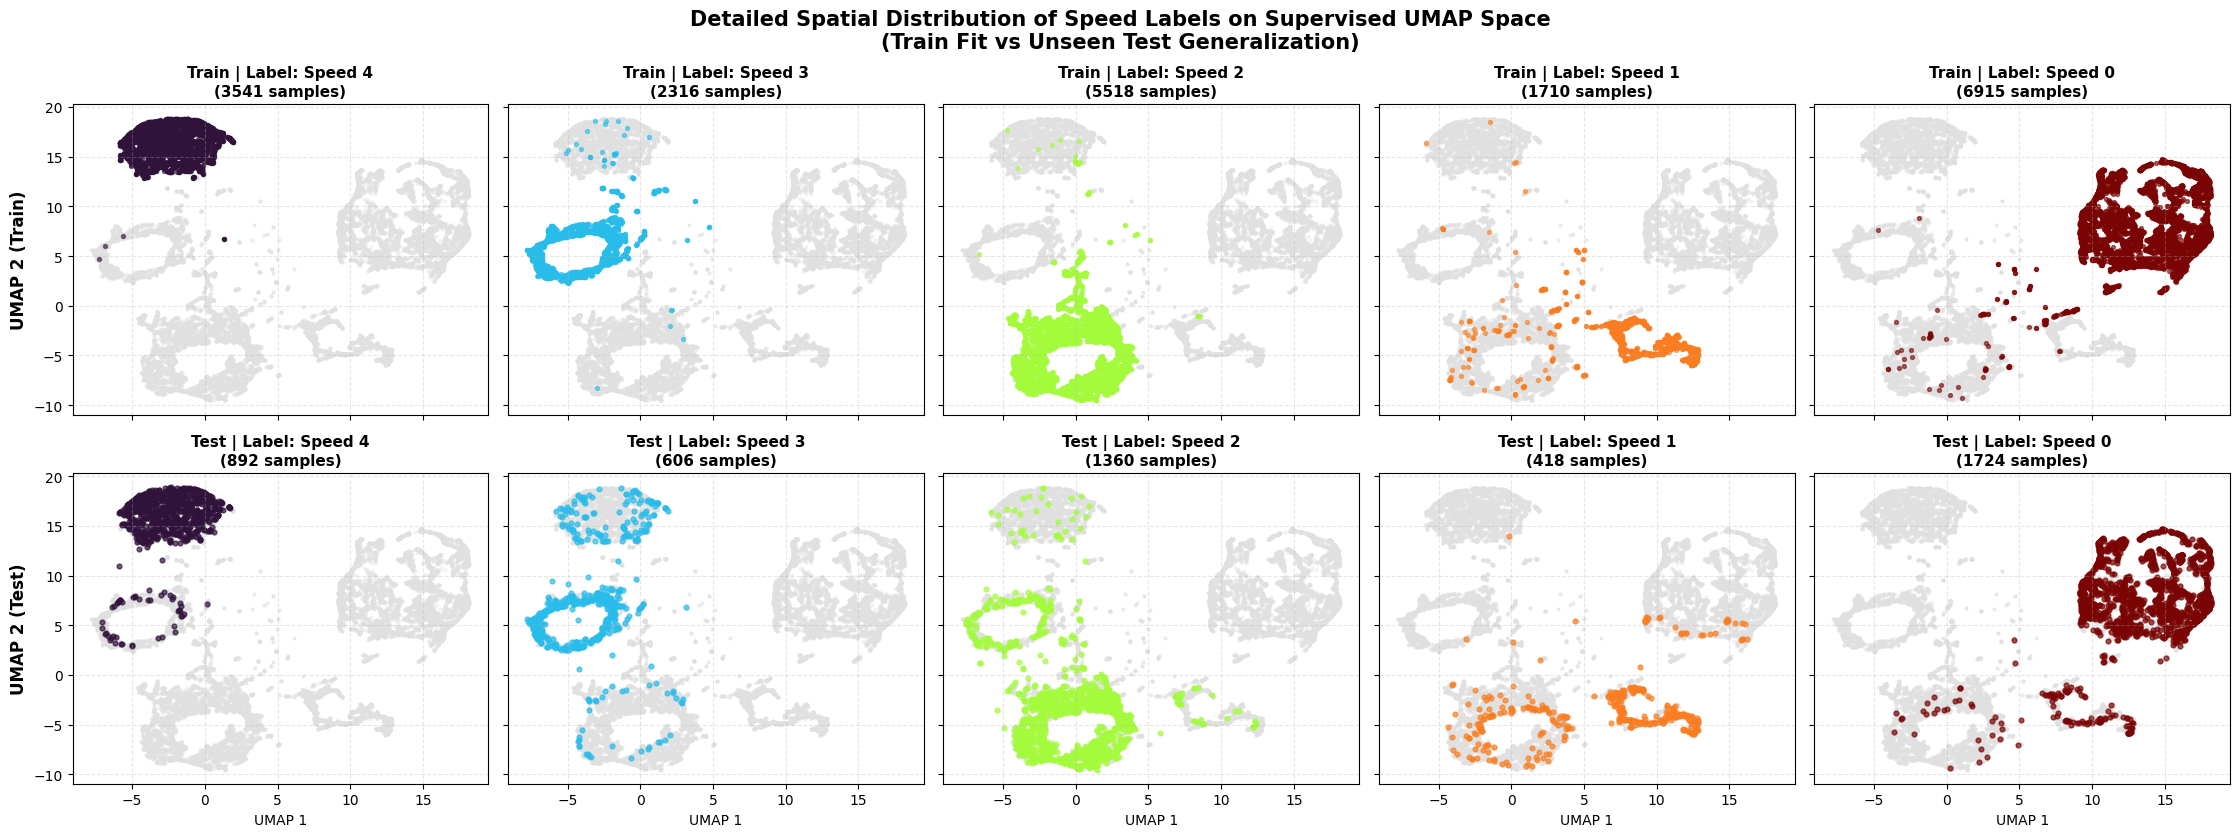


Plot saved as 'umap_train_vs_test_separate_column_3_SUPERVISED.png'


In [ ]:
# Train vs Test on the same UMAP space (Supervised) - Separate Facets
X_train_raw = np.load(train_embeddings_file)
y_train_raw = np.load(train_labels_file)[:, COLUMN].astype(int)

X_test_raw = np.load(test_embeddings_file)
y_test_raw = np.load(test_labels_file)[:, COLUMN].astype(int)

np.random.seed(42)
train_idx = np.random.choice(len(X_train_raw), size=min(TRAIN_SAMPLE, len(X_train_raw)), replace=False)
test_idx = np.random.choice(len(X_test_raw), size=min(TEST_SAMPLE, len(X_test_raw)), replace=False)

X_train = X_train_raw[train_idx]
y_train = y_train_raw[train_idx]
X_test = X_test_raw[test_idx]
y_test = y_test_raw[test_idx]

# ΚΑΝΟΝΙΚΟΠΟΙΗΣΗ
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =================== #
#   SUPERVISED UMAP   #
# =================== #
print("\nSupervised UMAP στα Train data...")
reducer = umap.UMAP(n_neighbors=40, min_dist=0.1, random_state=60)
X_umap_train = reducer.fit_transform(X_train_scaled, y=y_train)

print("Plotting Test data on UMAP space without labels...")
X_umap_test = reducer.transform(X_test_scaled)

# ================= #
#   VISUALISATION   #
# ================= #
unique_labels = np.sort(np.unique(y_train))
n_labels = len(unique_labels)

fig, axes = plt.subplots(2, n_labels, figsize=(4.5 * n_labels, 8.5), sharex=True, sharey=True)

cmap_base = plt.cm.get_cmap("turbo", n_labels)
colors_dict = {lbl: cmap_base(i) for i, lbl in enumerate(unique_labels)}

# --- ΣΕΙΡΑ 1: TRAIN LATENTS ---
for idx, lbl in enumerate(unique_labels):
    ax = axes[0, idx]
    # Γκρι background με όλα τα train σημεία
    ax.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c="#e0e0e0", s=4, alpha=0.3)

    # Έγχρωμα σημεία του συγκεκριμένου label
    mask = (y_train == lbl)
    n_points = np.sum(mask)
    ax.scatter(X_umap_train[mask, 0], X_umap_train[mask, 1], c=[colors_dict[lbl]], s=8, alpha=0.6)

    ax.set_title(f"Train | Label: {label_types[COLUMN][lbl]}\n({n_points} samples)", fontsize=11, fontweight='bold')
    ax.grid(True, linestyle="--", alpha=0.3)
    if idx == 0:
        ax.set_ylabel("UMAP 2 (Train)", fontsize=12, fontweight='bold')

# --- ΣΕΙΡΑ 2: TEST LATENTS ---
for idx, lbl in enumerate(unique_labels):
    ax = axes[1, idx]
    # Γκρι background με όλα τα test σημεία
    ax.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c="#e0e0e0", s=4, alpha=0.3)

    mask = (y_test == lbl)
    n_points = np.sum(mask)
    ax.scatter(X_umap_test[mask, 0], X_umap_test[mask, 1], c=[colors_dict[lbl]], s=12, alpha=0.7)

    ax.set_title(f"Test | Label: {label_types[COLUMN][lbl]}\n({n_points} samples)", fontsize=11, fontweight='bold')
    ax.set_xlabel("UMAP 1")
    ax.grid(True, linestyle="--", alpha=0.3)
    if idx == 0:
        ax.set_ylabel("UMAP 2 (Test)", fontsize=12, fontweight='bold')

plt.suptitle(f"Detailed Spatial Distribution of {column_titles[COLUMN]} on Supervised UMAP Space\n(Train Fit vs Unseen Test Generalization)",
             fontsize=15, fontweight='bold', y=0.98)

plt.tight_layout()
output_filename = f"umap_train_vs_test_separate_column_{COLUMN}_SUPERVISED.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nPlot saved as '{output_filename}'")


1/3: Εκτέλεση K-Means στις αρχικές 32 διαστάσεις του Train set...
2/3: Πρόβλεψη των Clusters για τα Test δεδομένα...
3/3: Εκπαίδευση Supervised UMAP χρησιμοποιώντας ως labels τα Cluster IDs...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\strat\AppData\Local\Temp\ipykernel_38188\699215963.py:53: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_base = plt.cm.get_cmap("turbo", n_clusters)


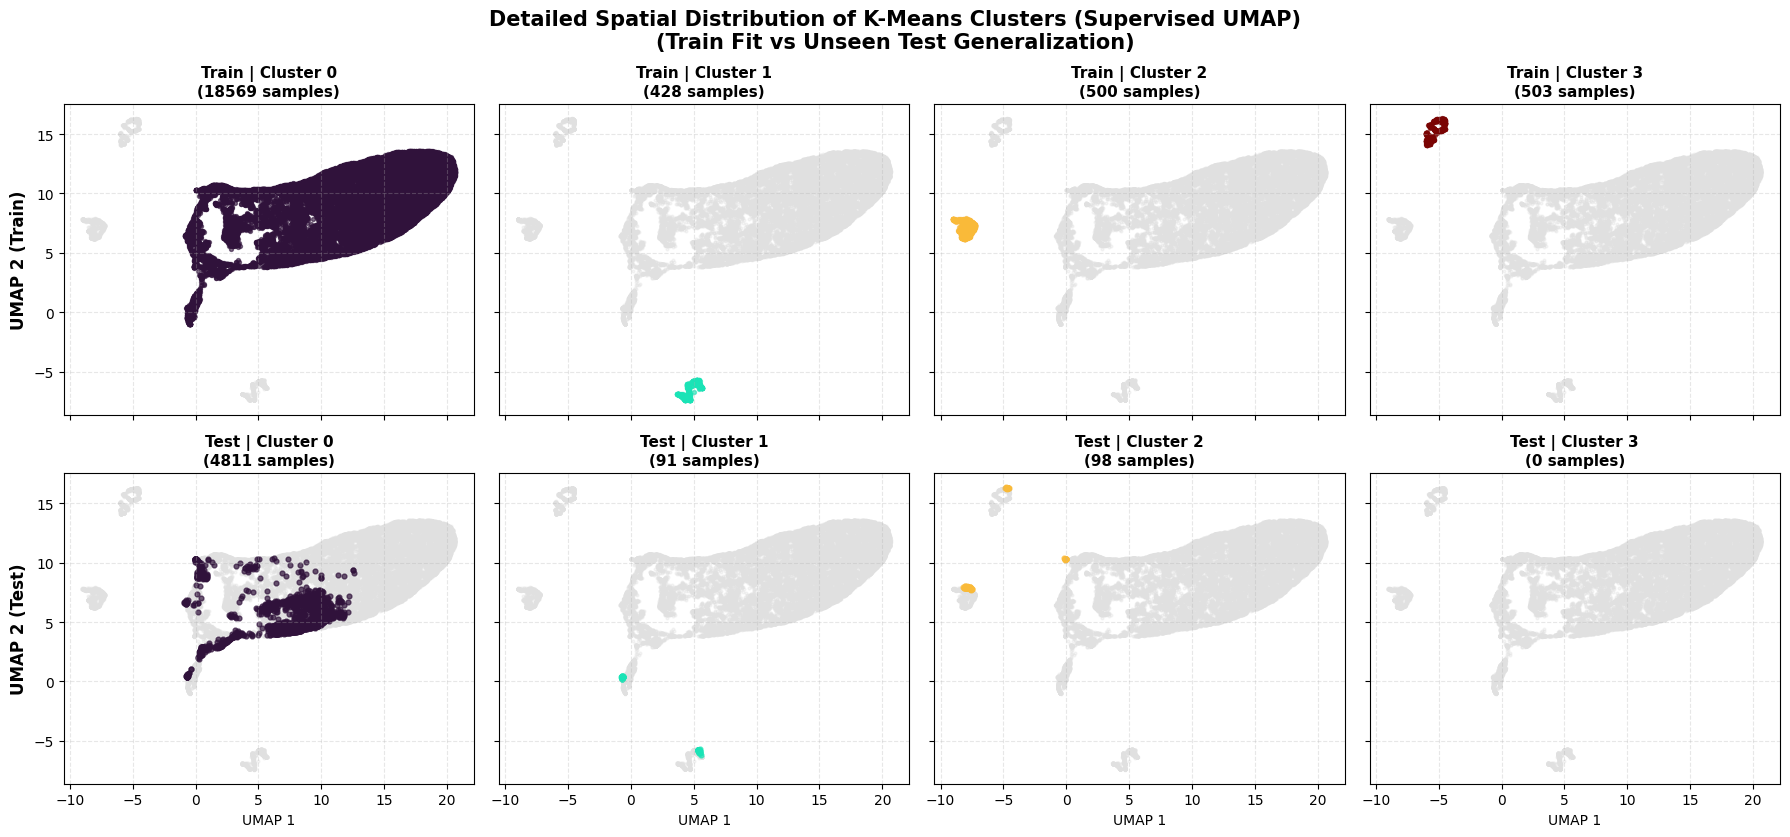


Plot saved as 'kmeans_train_vs_test_umap_separate_supervised.png'


In [ ]:
X_train_raw = np.load(train_embeddings_file)
X_test_raw = np.load(test_embeddings_file)

np.random.seed(42)
train_idx = np.random.choice(len(X_train_raw), size=min(TRAIN_SAMPLE, len(X_train_raw)), replace=False)
test_idx = np.random.choice(len(X_test_raw), size=min(TEST_SAMPLE, len(X_test_raw)), replace=False)

X_train = X_train_raw[train_idx]
X_test = X_test_raw[test_idx]

# ΚΑΝΟΝΙΚΟΠΟΙΗΣΗ
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n1/3: Εκτέλεση K-Means στις αρχικές διαστάσεις του Train set...")
NUM_CLUSTERS = 4  # Ή όσα clusters θέλεις να βρεις

kmeans = KMeans(n_clusters=NUM_CLUSTERS, random_state=42)

# Ο K-Means βρίσκει τα clusters στο Train
train_clusters = kmeans.fit_predict(X_train_scaled)

print("2/3: Πρόβλεψη των Clusters για τα Test δεδομένα...")
test_clusters = kmeans.predict(X_test_scaled)

# =================== #
#   SUPERVISED UMAP   #
# =================== #
print("3/3: Εκπαίδευση Supervised UMAP χρησιμοποιώντας ως labels τα Cluster IDs...")
reducer = umap.UMAP(n_neighbors=40, min_dist=0.1, random_state=60)

X_umap_train = reducer.fit_transform(X_train_scaled, y=train_clusters)

X_umap_test = reducer.transform(X_test_scaled)

# ================= #
#   VISUALISATION   #
# ================= #
unique_clusters = np.sort(np.unique(train_clusters))
n_clusters = len(unique_clusters)

fig, axes = plt.subplots(2, n_clusters, figsize=(4.5 * n_clusters, 8.5), sharex=True, sharey=True)

cmap_base = plt.cm.get_cmap("turbo", n_clusters)
colors_dict = {c_id: cmap_base(i) for i, c_id in enumerate(unique_clusters)}

# --- ΣΕΙΡΑ 1: TRAIN K-MEANS CLUSTERS ---
for idx, c_id in enumerate(unique_clusters):
    ax = axes[0, idx]
    # Γκρι background με όλα τα train σημεία
    ax.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c="#e0e0e0", s=4, alpha=0.3)

    mask = (train_clusters == c_id)
    n_points = np.sum(mask)
    ax.scatter(X_umap_train[mask, 0], X_umap_train[mask, 1], c=[colors_dict[c_id]], s=8, alpha=0.6)

    ax.set_title(f"Train | Cluster {c_id}\n({n_points} samples)", fontsize=11, fontweight='bold')
    ax.grid(True, linestyle="--", alpha=0.3)
    if idx == 0:
        ax.set_ylabel("UMAP 2 (Train)", fontsize=12, fontweight='bold')

# --- ΣΕΙΡΑ 2: TEST K-MEANS CLUSTERS ---
for idx, c_id in enumerate(unique_clusters):
    ax = axes[1, idx]
    # Γκρι background με όλα τα test σημεία
    ax.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c="#e0e0e0", s=4, alpha=0.3)

    mask = (test_clusters == c_id)
    n_points = np.sum(mask)
    ax.scatter(X_umap_test[mask, 0], X_umap_test[mask, 1], c=[colors_dict[c_id]], s=12, alpha=0.7)

    ax.set_title(f"Test | Cluster {c_id}\n({n_points} samples)", fontsize=11, fontweight='bold')
    ax.set_xlabel("UMAP 1")
    ax.grid(True, linestyle="--", alpha=0.3)
    if idx == 0:
        ax.set_ylabel("UMAP 2 (Test)", fontsize=12, fontweight='bold')

plt.suptitle("Detailed Spatial Distribution of K-Means Clusters (Supervised UMAP)\n(Train Fit vs Unseen Test Generalization)",
             fontsize=15, fontweight='bold', y=0.98)

plt.tight_layout()
output_filename = "kmeans_train_vs_test_umap_separate_supervised.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nPlot saved as '{output_filename}'")

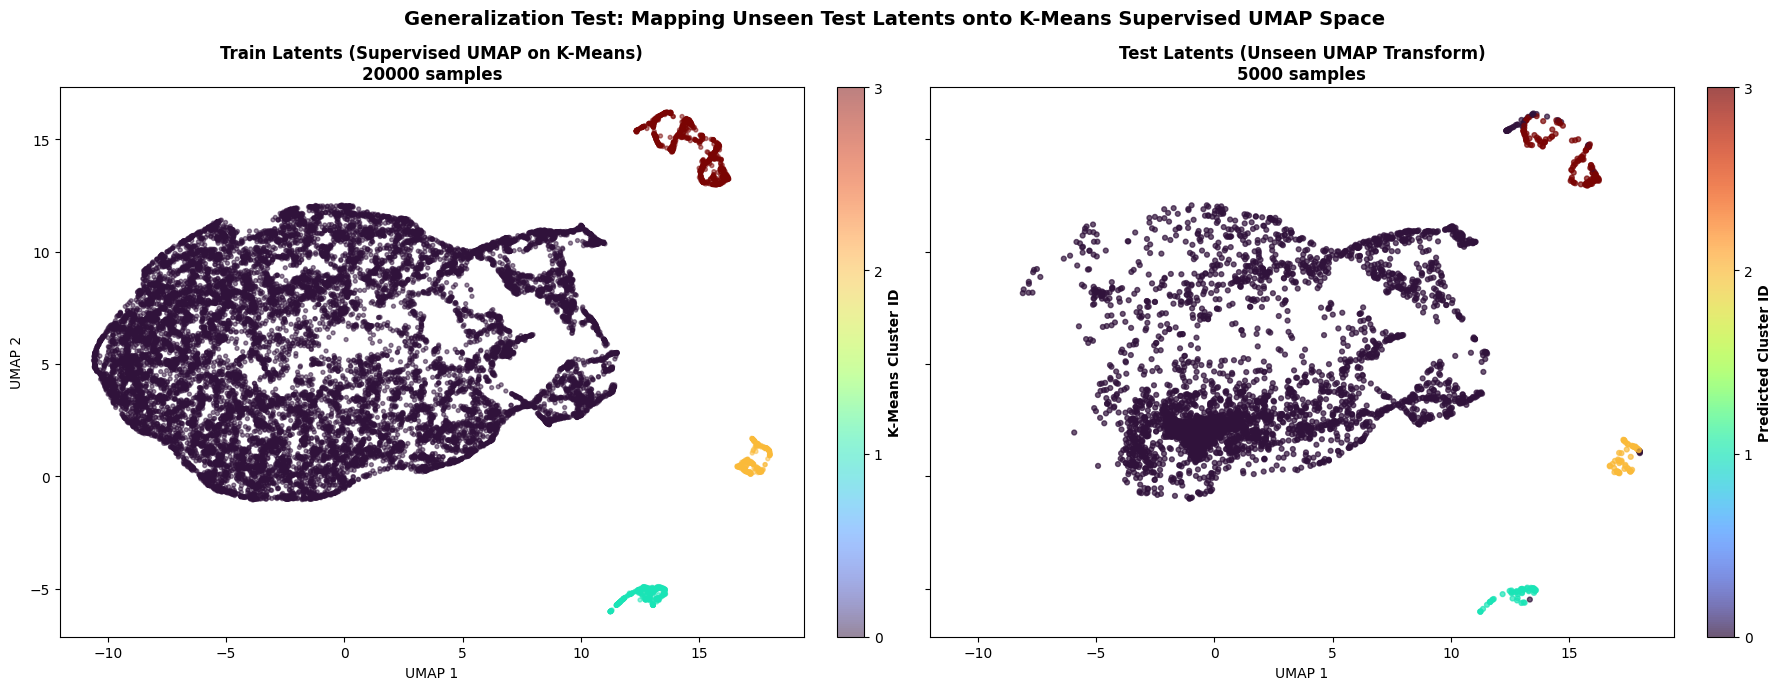


Το γράφημα αποθηκεύτηκε επιτυχώς ως 'kmeans_supervised_umap_generalization.png'


In [ ]:
# ================= #
#   VISUALISATION   #
# ================= #
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), sharex=True, sharey=True)
GLOBAL_CMAP = "turbo"

unique_clusters = np.unique(train_clusters)

# Αριστερό Panel: Train (Χρωματισμένο με βάση τα Clusters του Train)
scatter1 = ax1.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c=train_clusters, s=8, cmap=GLOBAL_CMAP, alpha=0.5)
ax1.set_title(f"Train Latents (Supervised UMAP on K-Means)\n{len(X_train)} samples", fontsize=12, fontweight='bold')
ax1.set_xlabel("UMAP 1")
ax1.set_ylabel("UMAP 2")
fig.colorbar(scatter1, ax=ax1, ticks=unique_clusters, fraction=0.046, pad=0.04).set_label('K-Means Cluster ID', fontweight='bold')

# Δεξί Panel: Test (Χρωματισμένο με βάση τα predicted Clusters του Test)
scatter2 = ax2.scatter(X_umap_test[:, 0], X_umap_test[:, 1], c=test_clusters, s=12, cmap=GLOBAL_CMAP, alpha=0.7)
ax2.set_title(f"Test Latents (Unseen UMAP Transform)\n{len(X_test)} samples", fontsize=12, fontweight='bold')
ax2.set_xlabel("UMAP 1")
fig.colorbar(scatter2, ax=ax2, ticks=unique_clusters, fraction=0.046, pad=0.04).set_label('Predicted Cluster ID', fontweight='bold')

plt.suptitle("Generalization Test: Mapping Unseen Test Latents onto K-Means Supervised UMAP Space", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

output_filename = "kmeans_supervised_umap_generalization.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nΤο γράφημα αποθηκεύτηκε επιτυχώς ως '{output_filename}'")

C:\Users\strat\AppData\Local\Temp\ipykernel_33508\2117318711.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_labels = plt.cm.get_cmap("turbo", n_labels)


Δημιουργία Facet Plot για το Label Column 0 (10 κλάσεις)...


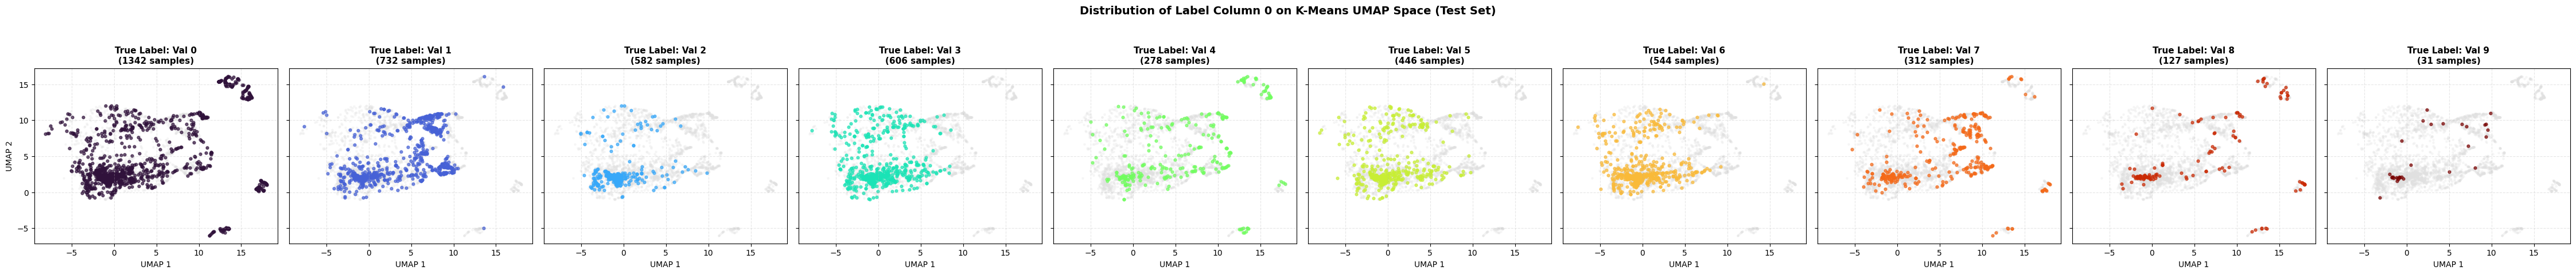

Δημιουργία Facet Plot για το Label Column 1 (5 κλάσεις)...


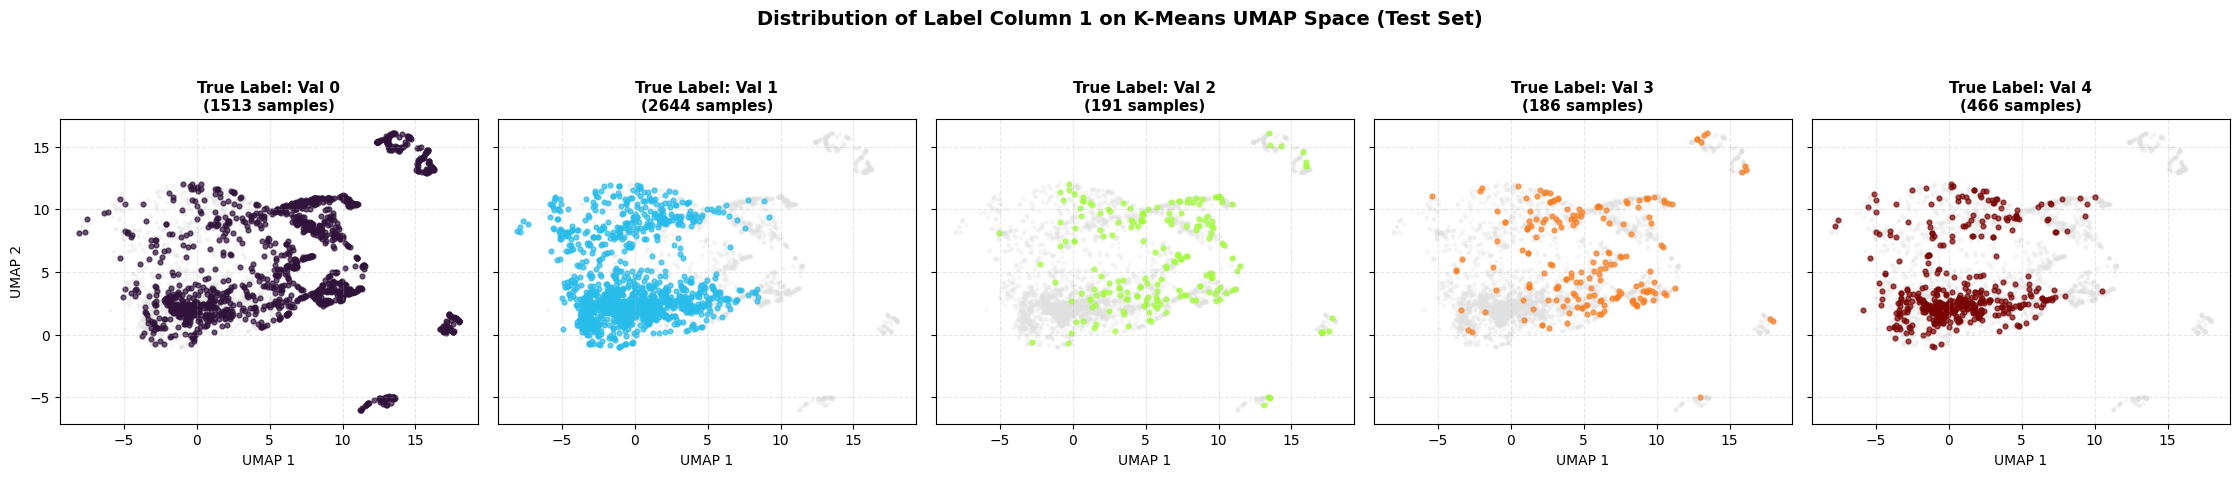

Δημιουργία Facet Plot για το Label Column 2 (3 κλάσεις)...


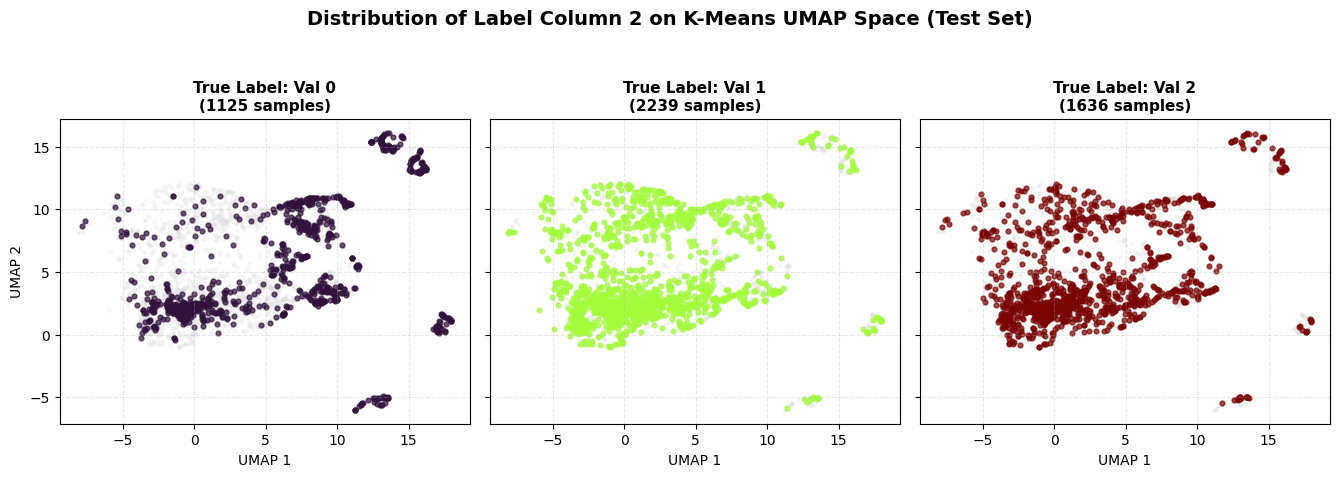

Δημιουργία Facet Plot για το Label Column 3 (5 κλάσεις)...


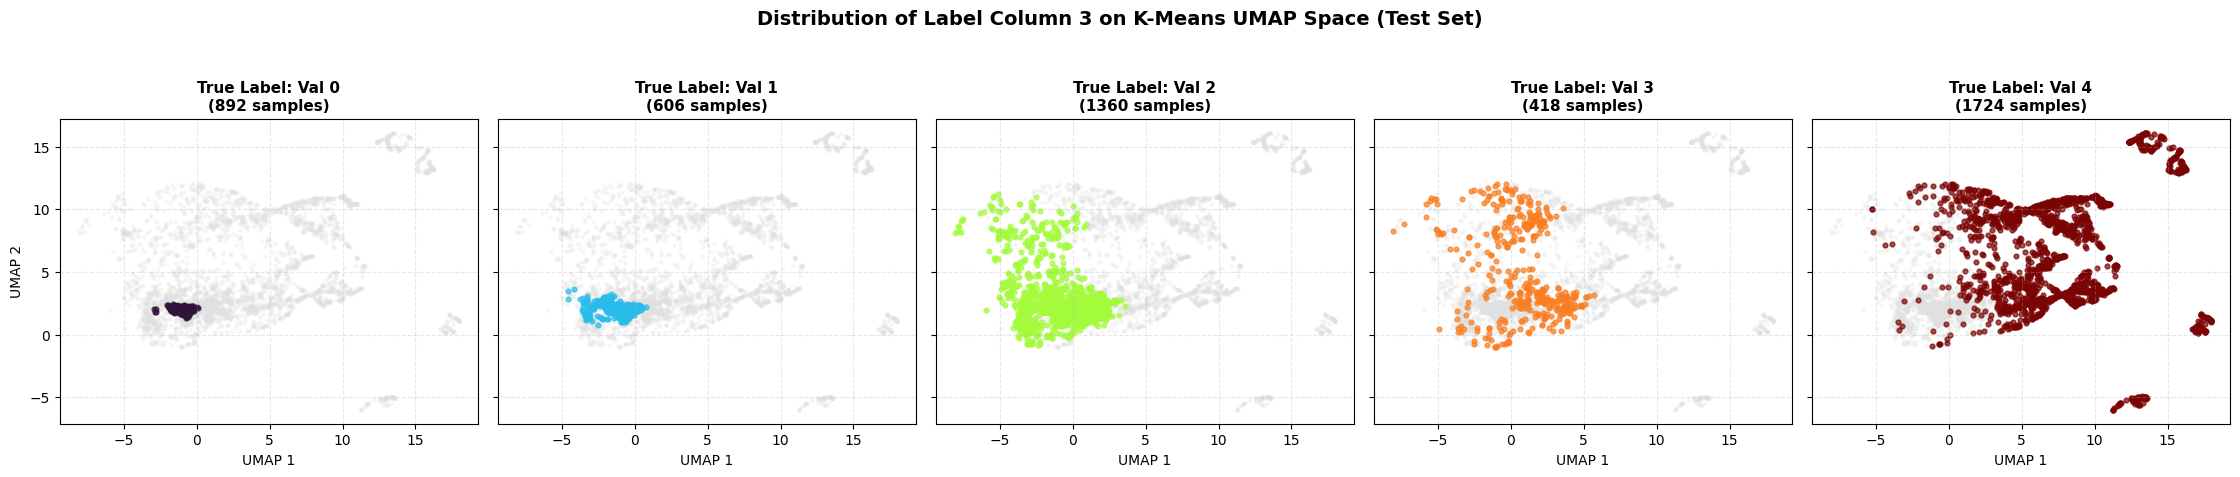


Όλα τα ξεχωριστά Facet Plots ανά Label Column δημιουργήθηκαν και αποθηκεύτηκαν!


In [ ]:
# ================= #
#   VISUALISATION   #
# ================= #
y_train_all_cols = np.load(train_labels_file)[train_idx]
y_test_all_cols = np.load(test_labels_file)[test_idx]

columns_to_plot = [0, 1, 2, 3]

for col_idx in columns_to_plot:
    # Απομονώνουμε τα labels για το τρέχον column
    y_test_current = y_test_all_cols[:, col_idx].astype(int)

    unique_labels = np.sort(np.unique(y_test_current))
    n_labels = len(unique_labels)

    # Δημιουργούμε το πλέγμα subplots για το συγκεκριμένο Label Column
    fig, axes = plt.subplots(1, n_labels, figsize=(4.5 * n_labels, 4.5), sharex=True, sharey=True)

    if n_labels == 1:
        axes = [axes]

    # Χρώματα για τις κλάσεις αυτού του column
    cmap_labels = plt.cm.get_cmap("turbo", n_labels)
    colors_labels = {lbl: cmap_labels(i) for i, lbl in enumerate(unique_labels)}

    print(f"Δημιουργία Facet Plot για το Label Column {col_idx} ({n_labels} κλάσεις)...")

    for idx, lbl in enumerate(unique_labels):
        ax = axes[idx]

        ax.scatter(X_umap_test[:, 0], X_umap_test[:, 1], c="#e0e0e0", s=5, alpha=0.2)

        mask = (y_test_current == lbl)
        n_points = np.sum(mask)
        ax.scatter(X_umap_test[mask, 0], X_umap_test[mask, 1], c=[colors_labels[lbl]], s=12, alpha=0.7)

        ax.set_title(f"True Label: Val {lbl}\n({n_points} samples)", fontsize=11, fontweight='bold')
        ax.set_xlabel("UMAP 1")
        ax.grid(True, linestyle="--", alpha=0.3)
        if idx == 0:
            ax.set_ylabel("UMAP 2")

    plt.suptitle(f"Distribution of Label Column {col_idx} on K-Means UMAP Space (Test Set)",
                 fontsize=14, fontweight='bold', y=1.05)

    plt.tight_layout()
    output_facet_name = f"umap_test_facet_column_{col_idx}.png"
    output_combined_name = os.path.join(folder_name, output_facet_name)
    plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
    plt.show()

print("\nΌλα τα ξεχωριστά Facet Plots ανά Label Column δημιουργήθηκαν και αποθηκεύτηκαν!")


Δημιουργία ενιαίων γραφημάτων σε μία σειρά για όλα τα Columns...


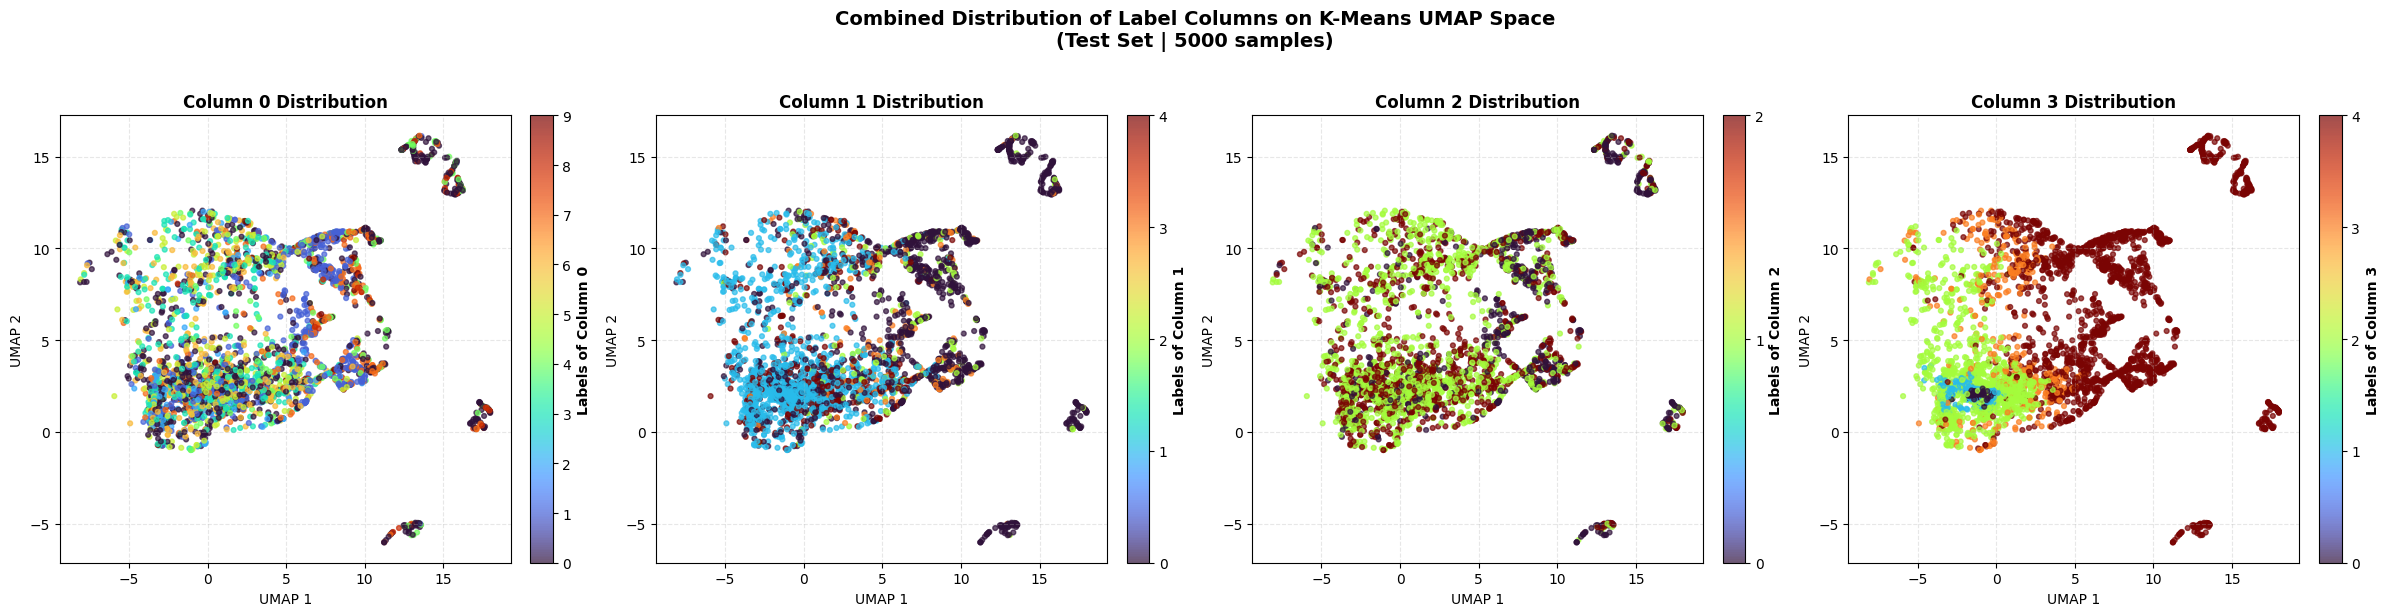


Το ενιαίο γράφημα δημιουργήθηκε και αποθηκεύτηκε ως 'umap_test_all_columns_combined.png'!


In [ ]:
import math
import matplotlib.pyplot as plt

# ================= #
#   VISUALISATION   #
# ================= #
print("\nΔημιουργία ενιαίων γραφημάτων σε μία σειρά για όλα τα Columns...")

num_cols_to_plot = len(columns_to_plot)
GLOBAL_CMAP = "turbo"

# Δημιουργούμε 1 σειρά με τόσα subplots όσα και τα columns_to_plot
# Ρυθμίζουμε το figsize δυναμικά (π.σ. 6 ίντσες πλάτος ανά γράφημα)
fig, axes = plt.subplots(1, num_cols_to_plot, figsize=(6 * num_cols_to_plot, 6))

# Αν υπάρχει μόνο 1 column, το axes δεν είναι array, οπότε το μετατρέπουμε για να δουλεύει το zip
if num_cols_to_plot == 1:
    axes = [axes]

for ax, col_idx in zip(axes, columns_to_plot):
    # Απομονώνουμε τα labels για το τρέχον column
    y_test_current = y_test_all_cols[:, col_idx].astype(int)
    unique_labels = np.sort(np.unique(y_test_current))

    # Σχεδιάζουμε όλα τα σημεία μαζί στο συγκεκριμένο ax
    scatter = ax.scatter(
        X_umap_test[:, 0],
        X_umap_test[:, 1],
        c=y_test_current,
        s=12,
        cmap=GLOBAL_CMAP,
        alpha=0.7
    )

    # Προσθήκη colorbar προσαρμοσμένου στα συγκεκριμένα labels του column
    cbar = fig.colorbar(scatter, ax=ax, ticks=unique_labels, fraction=0.046, pad=0.04)
    cbar.set_label(f'Labels of Column {col_idx}', fontweight='bold')

    # Μορφοποίηση του συγκεκριμένου subplot
    ax.set_title(f"Column {col_idx} Distribution", fontsize=12, fontweight='bold')
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.grid(True, linestyle="--", alpha=0.3)

# Συνολικός τίτλος για όλη την εικόνα
fig.suptitle(f"Combined Distribution of Label Columns on K-Means UMAP Space\n(Test Set | {len(X_umap_test)} samples)",
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
output_filename = "umap_test_all_columns_combined.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nΤο ενιαίο γράφημα δημιουργήθηκε και αποθηκεύτηκε ως '{output_combined_name}'!")

Train Latents Shape: (65790, 16) | Labels: (65790,)
Test Latents Shape:  (7311, 16) | Labels: (7311,)

Εκτέλεση Unsupervised UMAP στα Train δεδομένα...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Προβολή των Test δεδομένων στον Unsupervised χώρο...


C:\Users\strat\AppData\Local\Temp\ipykernel_38188\974036637.py:47: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_base = plt.cm.get_cmap("turbo", n_labels)


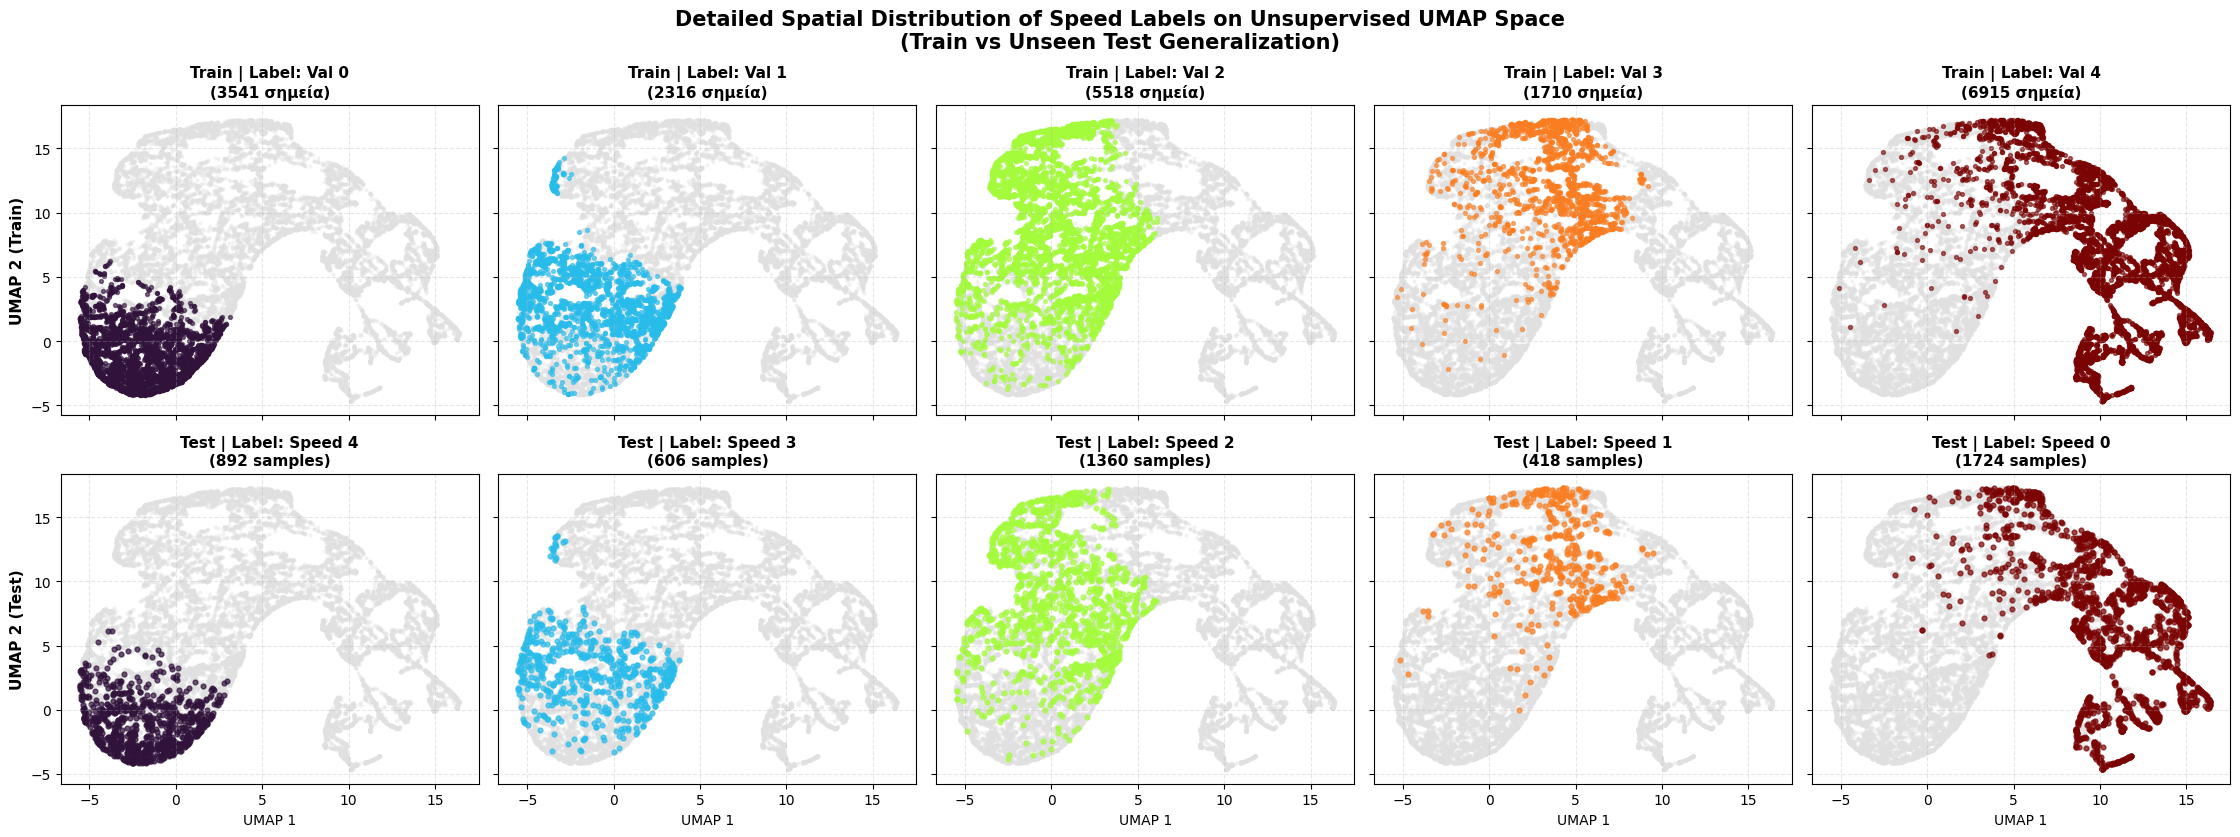

Plot saved as 'unsupervised_umap_train_vs_test_separate.png'


In [ ]:
# Train vs Test on the same UMAP space (Unsupervised) - Separate Facets
X_train_raw = np.load(train_embeddings_file)
y_train_raw = np.load(train_labels_file)[:, 3].astype(int) # Column 3 για Train

X_test_raw = np.load(test_embeddings_file)
y_test_raw = np.load(test_labels_file)[:, 3].astype(int)   # Column 3 για Test

print(f"Train Latents Shape: {X_train_raw.shape} | Labels: {y_train_raw.shape}")
print(f"Test Latents Shape:  {X_test_raw.shape} | Labels: {y_test_raw.shape}")

np.random.seed(42)
train_idx = np.random.choice(len(X_train_raw), size=min(TRAIN_SAMPLE, len(X_train_raw)), replace=False)
test_idx = np.random.choice(len(X_test_raw), size=min(TEST_SAMPLE, len(X_test_raw)), replace=False)

X_train = X_train_raw[train_idx]
y_train = y_train_raw[train_idx]

X_test = X_test_raw[test_idx]
y_test = y_test_raw[test_idx]

# Κανονικοποίηση
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ===================== #
#   UNSUPERVISED UMAP   #
# ===================== #
print("\nΕκτέλεση Unsupervised UMAP στα Train δεδομένα...")
# Χωρίς y=y_train, το UMAP κοιτάει μόνο τη γεωμετρία των 32 διαστάσεων
reducer = umap.UMAP(n_neighbors=40, min_dist=0.1, random_state=60)
X_umap_train = reducer.fit_transform(X_train_scaled)

print("Προβολή των Test δεδομένων στον Unsupervised χώρο...")
X_umap_test = reducer.transform(X_test_scaled)

# ============================================ #
#   ΔΗΜΙΟΥΡΓΙΑ ΠΛΕΓΜΑΤΟΣ ΔΙΑΧΩΡΙΣΜΕΝΩΝ PLOTS   #
# ============================================ #
unique_labels = np.sort(np.unique(y_train))
n_labels = len(unique_labels)

fig, axes = plt.subplots(2, n_labels, figsize=(4.5 * n_labels, 8.5), sharex=True, sharey=True)

cmap_base = plt.cm.get_cmap("turbo", n_labels)
colors_dict = {lbl: cmap_base(i) for i, lbl in enumerate(unique_labels)}

# --- ΣΕΙΡΑ 1: TRAIN LATENTS ---
for idx, lbl in enumerate(unique_labels):
    ax = axes[0, idx]
    ax.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c="#e0e0e0", s=4, alpha=0.3)

    mask = (y_train == lbl)
    n_points = np.sum(mask)
    ax.scatter(X_umap_train[mask, 0], X_umap_train[mask, 1], c=[colors_dict[lbl]], s=8, alpha=0.6)

    ax.set_title(f"Train | Label: {label_types[COLUMN][lbl]}\n({n_points} samples)", fontsize=11, fontweight='bold')
    ax.grid(True, linestyle="--", alpha=0.3)
    if idx == 0:
        ax.set_ylabel("UMAP 2 (Train)", fontsize=11, fontweight='bold')

# --- ΣΕΙΡΑ 2: TEST LATENTS ---
for idx, lbl in enumerate(unique_labels):
    ax = axes[1, idx]
    ax.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c="#e0e0e0", s=4, alpha=0.3)

    mask = (y_test == lbl)
    n_points = np.sum(mask)
    ax.scatter(X_umap_test[mask, 0], X_umap_test[mask, 1], c=[colors_dict[lbl]], s=12, alpha=0.7)

    ax.set_title(f"Test | Label: {label_types[COLUMN][lbl]}\n({n_points} samples)", fontsize=11, fontweight='bold')
    ax.set_xlabel("UMAP 1")
    ax.grid(True, linestyle="--", alpha=0.3)
    if idx == 0:
        ax.set_ylabel("UMAP 2 (Test)", fontsize=11, fontweight='bold')

plt.suptitle(f"Detailed Spatial Distribution of {column_titles[COLUMN]} on Unsupervised UMAP Space\n(Train vs Unseen Test Generalization)",
             fontsize=15, fontweight='bold', y=0.98)

plt.tight_layout()
output_filename = "unsupervised_umap_train_vs_test_separate.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"Plot saved as '{output_filename}'")


Supervised UMAP στα Train data...


c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Plotting Test data on UMAP space without labels...

Εκτέλεση K-Means πάνω στον 2D UMAP χώρο του Train set...
Πρόβλεψη K-Means clusters για το Test set...

Υπολογισμός βέλτιστης αντιστοίχισης (Cluster Alignment) για το Test set...

ΚΑΛΥΤΕΡΗ ΔΥΝΑΤΗ ΑΚΡΙΒΕΙΑ (Test Accuracy): 35.30%

Βέλτιστο Mapping που βρέθηκε:
  • K-Means Cluster 0  --->  Πραγματικό Label: Speed 2
  • K-Means Cluster 1  --->  Πραγματικό Label: Speed 4
  • K-Means Cluster 2  --->  Πραγματικό Label: Speed 0
  • K-Means Cluster 3  --->  Πραγματικό Label: Speed 3
  • K-Means Cluster 4  --->  Πραγματικό Label: Speed 1

Αναλυτικό Classification Report (aligned):
              precision    recall  f1-score   support

     Speed 4       0.00      0.00      0.00       892
     Speed 3       0.00      0.00      0.00       606
     Speed 2       0.30      0.99      0.47      1360
     Speed 1       0.00      0.00      0.00       418
     Speed 0       0.95      0.24      0.39      1724

    accuracy                           0.35 

c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\strat\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

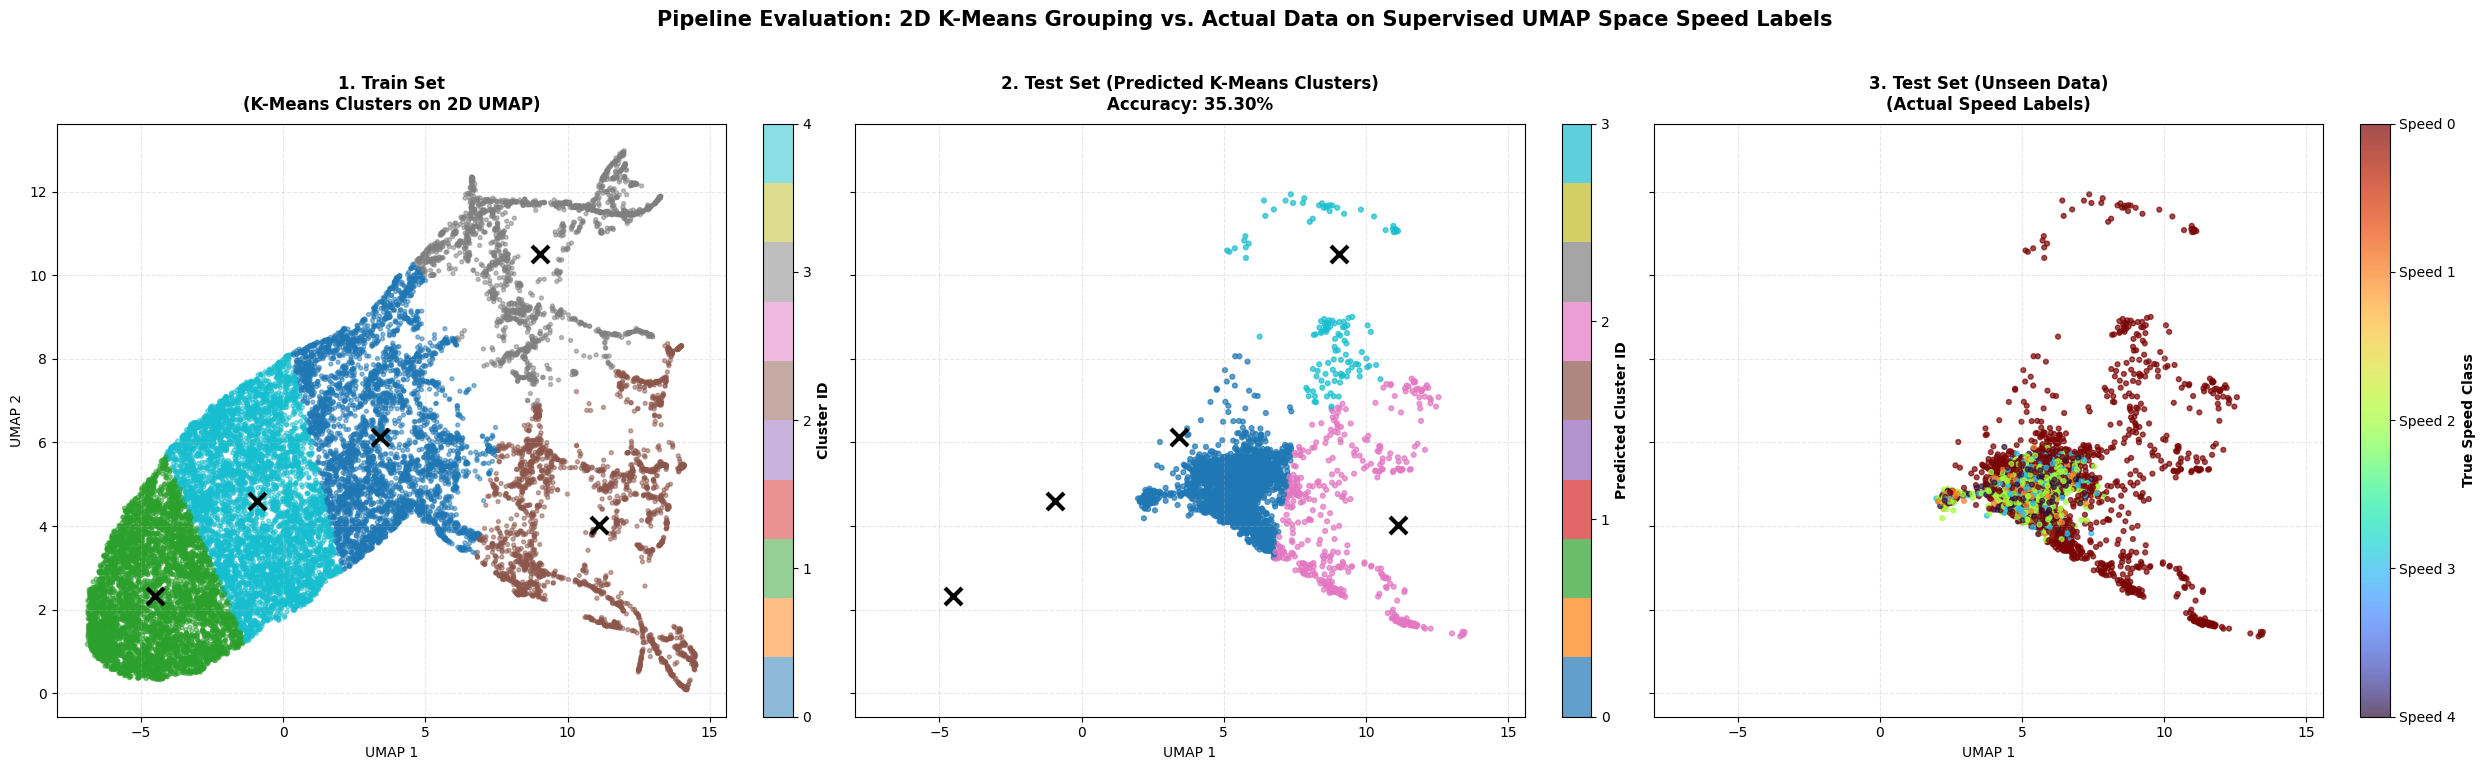


Το 3-panel γράφημα αποθηκεύτηκε επιτυχώς ως 'umap_kmeans_vs_actual_3_3panel_noisy.png' μέσα στον φάκελο 'latents_8/'!


In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import accuracy_score, classification_report

TEXT_LABELS = [
    ["Vehicle", "Pedestrian", "Construction", "Riderless Bicycle", "Bus", "Background", "Static", "Cyclist", "Motorcyclist", "Unknown"],
    ["Straight", "U Turn", "Left Turn", "Right Turn", "Unspecified"],
    ["Constant Speed", "Decelerate", "Accelerate"],
    ["Speed 4", "Speed 3", "Speed 2", "Speed 1", "Speed 0"]
]

COLUMN = 3

X_train_raw = np.load(train_embeddings_file)
y_train_raw = np.load(train_labels_file)[:, COLUMN].astype(int)

X_test_raw = np.load(test_embeddings_file)
y_test_raw = np.load(test_labels_file)[:, COLUMN].astype(int)

np.random.seed(42)
train_idx = np.random.choice(len(X_train_raw), size=min(TRAIN_SAMPLE, len(X_train_raw)), replace=False)
test_idx = np.random.choice(len(X_test_raw), size=min(TEST_SAMPLE, len(X_test_raw)), replace=False)

X_train = X_train_raw[train_idx]
y_train = y_train_raw[train_idx]
X_test = X_test_raw[test_idx]
y_test = y_test_raw[test_idx]

# ΚΑΝΟΝΙΚΟΠΟΙΗΣΗ
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =================== #
#   SUPERVISED UMAP   #
# =================== #
print("\nSupervised UMAP στα Train data...")
reducer = umap.UMAP(n_neighbors=40, min_dist=0.1, random_state=60)
# X_umap_train = reducer.fit_transform(X_train_scaled, y=y_train)
X_umap_train = reducer.fit_transform(X_train_scaled)

print("Plotting Test data on UMAP space without labels...")
X_umap_test = reducer.transform(X_test_scaled)

# ======================================================== #
#   ΕΚΤΕΛΕΣΗ K-MEANS ΠΑΝΩ ΣΤΙΣ 2D ΣΥΝΤΕΤΑΓΜΕΝΕΣ ΤΟΥ UMAP   #
# ======================================================== #
print("\nΕκτέλεση K-Means πάνω στον 2D UMAP χώρο του Train set...")
NUM_CLUSTERS = len(np.unique(y_train))  # Ο αριθμός των clusters ισούται με τον αριθμό των μοναδικών labels στο συγκεκριμένο column

# Εκπαίδευση του K-Means στα 2D Train δεδομένα
kmeans_umap = KMeans(n_clusters=NUM_CLUSTERS, random_state=42, n_init=10)
train_umap_clusters = kmeans_umap.fit_predict(X_umap_train)

# Πρόβλεψη των clusters για τα 2D Test δεδομένα
print("Πρόβλεψη K-Means clusters για το Test set...")
test_umap_clusters = kmeans_umap.predict(X_umap_test)

# ========================================================= #
#   ΥΠΟΛΟΓΙΣΜΟΣ ΒΕΛΤΙΣΤΗΣ ΑΝΤΙΣΤΟΙΧΙΣΗΣ & ACCURACY (TEST)   #
# ========================================================= #
print("\nΥπολογισμός βέλτιστης αντιστοίχισης (Cluster Alignment) για το Test set...")

def get_cluster_accuracy(true_labels, predicted_clusters):
    D = max(predicted_clusters.max(), true_labels.max()) + 1
    w = np.zeros((D, D), dtype=np.int64)
    for i in range(predicted_clusters.size):
        w[predicted_clusters[i], true_labels[i]] += 1

    row_ind, col_ind = linear_sum_assignment(w.max() - w)

    mapping = {row: col for row, col in zip(row_ind, col_ind)}

    aligned_preds = np.array([mapping[cluster] for cluster in predicted_clusters])

    return accuracy_score(true_labels, aligned_preds), aligned_preds, mapping

# Εκτέλεση του alignment
test_accuracy, aligned_test_preds, cluster_mapping = get_cluster_accuracy(y_test, test_umap_clusters)

print("\n" + "="*50)
print(f"ΚΑΛΥΤΕΡΗ ΔΥΝΑΤΗ ΑΚΡΙΒΕΙΑ (Test Accuracy): {test_accuracy * 100:.2f}%")
print("="*50)

print("\nΒέλτιστο Mapping που βρέθηκε:")
for cluster_id, true_label_id in cluster_mapping.items():
    if true_label_id < len(TEXT_LABELS[COLUMN]):
        label_name = TEXT_LABELS[COLUMN][true_label_id]
    else:
        label_name = f"Val {true_label_id}"
    print(f"  • K-Means Cluster {cluster_id}  --->  Πραγματικό Label: {label_name}")

print("\nΑναλυτικό Classification Report (aligned):")
print(classification_report(y_test, aligned_test_preds,
                            target_names=[TEXT_LABELS[COLUMN][i] for i in np.unique(y_test) if i < len(TEXT_LABELS[COLUMN])]))

# ================= #
#   VISUALISATION   #
# ================= #
# Αυξάνουμε το πλάτος (figsize) σε 25 για να χωρέσουν άνετα 3 subplots χωρίς να στριμωχτούν
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(25, 7.5), sharex=True, sharey=True)

GLOBAL_CMAP_CLUSTERS = "tab10"  # Colormap για τα K-Means Clusters
GLOBAL_CMAP_TRUTH = "turbo"     # Colormap για τα Actual Speed Data

unique_clusters = np.unique(train_umap_clusters)
unique_labels_gt = np.unique(y_test)

# --------------------------------------------------------
# PLOT 1: Train Set - K-Means Clusters
# --------------------------------------------------------
scatter1 = ax1.scatter(X_umap_train[:, 0], X_umap_train[:, 1], c=train_umap_clusters, s=8, cmap=GLOBAL_CMAP_CLUSTERS, alpha=0.5)
# Σχεδιασμός των centroids
centroids = kmeans_umap.cluster_centers_
ax1.scatter(centroids[:, 0], centroids[:, 1], marker='x', s=150, linewidths=3, color='black', zorder=10)

ax1.set_title("1. Train Set\n(K-Means Clusters on 2D UMAP)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("UMAP 1")
ax1.set_ylabel("UMAP 2")
ax1.grid(True, linestyle="--", alpha=0.3)
cbar1 = fig.colorbar(scatter1, ax=ax1, ticks=unique_clusters, fraction=0.046, pad=0.05)
cbar1.set_label('Cluster ID', fontweight='bold')

# --------------------------------------------------------
# PLOT 2: Test Set - Predicted Clusters
# --------------------------------------------------------
scatter2 = ax2.scatter(X_umap_test[:, 0], X_umap_test[:, 1], c=test_umap_clusters, s=12, cmap=GLOBAL_CMAP_CLUSTERS, alpha=0.7)
# Επαναλαμβάνουμε τα centroids για γεωμετρική αναφορά
ax2.scatter(centroids[:, 0], centroids[:, 1], marker='x', s=150, linewidths=3, color='black', zorder=10)

ax2.set_title("2. Test Set (Predicted K-Means Clusters)\nAccuracy: {0:.2f}%".format(test_accuracy * 100), fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("UMAP 1")
ax2.grid(True, linestyle="--", alpha=0.3)
cbar2 = fig.colorbar(scatter2, ax=ax2, ticks=unique_clusters, fraction=0.046, pad=0.05)
cbar2.set_label('Predicted Cluster ID', fontweight='bold')

# --------------------------------------------------------
# PLOT 3: Test Set - Actual Labels
# --------------------------------------------------------
scatter3 = ax3.scatter(X_umap_test[:, 0], X_umap_test[:, 1], c=y_test, s=12, cmap=GLOBAL_CMAP_TRUTH, alpha=0.7)

ax3.set_title(f"3. Test Set (Unseen Data)\n(Actual {column_titles[COLUMN]})", fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel("UMAP 1")
ax3.grid(True, linestyle="--", alpha=0.3)

# Ρύθμιση Colorbar με τα σωστά text strings αντί για νούμερα
cbar3 = fig.colorbar(scatter3, ax=ax3, ticks=unique_labels_gt, fraction=0.046, pad=0.05)
cbar3.ax.set_yticklabels([TEXT_LABELS[COLUMN][int(i)] if int(i) < len(TEXT_LABELS[COLUMN]) else f"Val {int(i)}" for i in unique_labels_gt])
cbar3.set_label('True Speed Class', fontweight='bold')

# Κεντρικός Τίτλος
plt.suptitle(f"Pipeline Evaluation: 2D K-Means Grouping vs. Actual Data on Supervised UMAP Space {column_titles[COLUMN]}",
             fontsize=15, fontweight='bold', y=1.02)

plt.tight_layout()

# Αποθήκευση
output_filename = f"umap_kmeans_vs_actual_{COLUMN}_3panel_noisy.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nΤο 3-panel γράφημα αποθηκεύτηκε επιτυχώς ως '{output_filename}' μέσα στον φάκελο '{folder_name}/'!")

In [ ]:
#dim=2

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import accuracy_score, classification_report

TEXT_LABELS = [
    ["Vehicle", "Pedestrian", "Construction", "Riderless Bicycle", "Bus", "Background", "Static", "Cyclist", "Motorcyclist", "Unknown"],
    ["Straight", "U Turn", "Left Turn", "Right Turn", "Unspecified"],
    ["Constant Speed", "Decelerate", "Accelerate"],
    ["Speed 4", "Speed 3", "Speed 2", "Speed 1", "Speed 0"]
]

COLUMN = 0

X_train_raw = np.load(train_embeddings_file)
y_train_raw = np.load(train_labels_file)[:, COLUMN].astype(int)

X_test_raw = np.load(test_embeddings_file)
y_test_raw = np.load(test_labels_file)[:, COLUMN].astype(int)

np.random.seed(42)
train_idx = np.random.choice(len(X_train_raw), size=min(TRAIN_SAMPLE, len(X_train_raw)), replace=False)
test_idx = np.random.choice(len(X_test_raw), size=min(TEST_SAMPLE, len(X_test_raw)), replace=False)

X_train = X_train_raw[train_idx]
y_train = y_train_raw[train_idx]
X_test = X_test_raw[test_idx]
y_test = y_test_raw[test_idx]

print(f"Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")

# Κανονικοποιηση
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ======= #
#   PCA   #
# ======= #
print("\nΥπολογισμός 2D συντεταγμένων μέσω PCA για το plotting...")
pca = PCA(n_components=2, random_state=42)
X_2d_train = pca.fit_transform(X_train_scaled)
X_2d_test = pca.transform(X_test_scaled)

NUM_CLUSTERS = len(np.unique(y_train))

kmeans = KMeans(n_clusters=NUM_CLUSTERS, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train_scaled)

test_clusters = kmeans.predict(X_test_scaled)

centroids_2d = pca.transform(kmeans.cluster_centers_)

# ============ #
#   ACCURACY   #
# ============ #
print("\nΥπολογισμός ακριβείας...")

def get_cluster_accuracy(true_labels, predicted_clusters):
    D = max(predicted_clusters.max(), true_labels.max()) + 1
    w = np.zeros((D, D), dtype=np.int64)
    for i in range(predicted_clusters.size):
        w[predicted_clusters[i], true_labels[i]] += 1

    row_ind, col_ind = linear_sum_assignment(w.max() - w)
    mapping = {row: col for row, col in zip(row_ind, col_ind)}
    aligned_preds = np.array([mapping[cluster] for cluster in predicted_clusters])

    return accuracy_score(true_labels, aligned_preds), aligned_preds, mapping

test_accuracy, aligned_test_preds, cluster_mapping = get_cluster_accuracy(y_test, test_clusters)

print("\n" + "="*50)
print(f"ΚΑΛΥΤΕΡΗ ΔΥΝΑΤΗ ΑΚΡΙΒΕΙΑ (Direct Test Accuracy): {test_accuracy * 100:.2f}%")
print("="*50)

print("\nΑναλυτικό Classification Report (aligned):")
print(classification_report(y_test, aligned_test_preds,
                            target_names=[TEXT_LABELS[COLUMN][i] for i in np.unique(y_test) if i < len(TEXT_LABELS[COLUMN])]))

# ================= #
#   VISUALISATION   #
# ================= #
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(25, 7.5), sharex=True, sharey=True)

GLOBAL_CMAP_CLUSTERS = "tab10"
GLOBAL_CMAP_TRUTH = "turbo"

unique_clusters = np.unique(train_clusters)
unique_labels_gt = np.unique(y_test)

# --------------------------------------------------------
# PLOT 1: Train Set - K-Means Clusters
# --------------------------------------------------------
scatter1 = ax1.scatter(X_2d_train[:, 0], X_2d_train[:, 1], c=train_clusters, s=8, cmap=GLOBAL_CMAP_CLUSTERS, alpha=0.5)
ax1.scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='x', s=150, linewidths=3, color='black', zorder=10)

ax1.set_title("1. Train Set\n(Direct K-Means Clusters - PCA View)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("PC 1")
ax1.set_ylabel("PC 2")
ax1.grid(True, linestyle="--", alpha=0.3)
cbar1 = fig.colorbar(scatter1, ax=ax1, ticks=unique_clusters, fraction=0.046, pad=0.05)
cbar1.set_label('Cluster ID', fontweight='bold')

# --------------------------------------------------------
# PLOT 2: Test Set - Predicted Clusters
# --------------------------------------------------------
scatter2 = ax2.scatter(X_2d_test[:, 0], X_2d_test[:, 1], c=test_clusters, s=12, cmap=GLOBAL_CMAP_CLUSTERS, alpha=0.7)
ax2.scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='x', s=150, linewidths=3, color='black', zorder=10)

ax2.set_title("2. Test Set (Predicted K-Means Clusters)\nAccuracy: {0:.2f}%".format(test_accuracy * 100), fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("PC 1")
ax2.grid(True, linestyle="--", alpha=0.3)
cbar2 = fig.colorbar(scatter2, ax=ax2, ticks=unique_clusters, fraction=0.046, pad=0.05)
cbar2.set_label('Predicted Cluster ID', fontweight='bold')

# --------------------------------------------------------
# PLOT 3: Test Set - Actual Labels
# --------------------------------------------------------
scatter3 = ax3.scatter(X_2d_test[:, 0], X_2d_test[:, 1], c=y_test, s=12, cmap=GLOBAL_CMAP_TRUTH, alpha=0.7)

ax3.set_title(f"3. Test Set (Unseen Data)\n(Actual {column_titles[COLUMN]})", fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel("PC 1")
ax3.grid(True, linestyle="--", alpha=0.3)

cbar3 = fig.colorbar(scatter3, ax=ax3, ticks=unique_labels_gt, fraction=0.046, pad=0.05)
cbar3.ax.set_yticklabels([TEXT_LABELS[COLUMN][int(i)] if int(i) < len(TEXT_LABELS[COLUMN]) else f"Val {int(i)}" for i in unique_labels_gt])
cbar3.set_label(f'True {column_titles[COLUMN]} Class', fontweight='bold')

plt.suptitle(f"2D K-Means vs. Actual Data ({column_titles[COLUMN]})",
             fontsize=15, fontweight='bold', y=1.02)

plt.tight_layout()

# Αποθήκευση
output_filename = f"direct_kmeans_vs_actual_{COLUMN}_3panel.png"
output_combined_name = os.path.join(folder_name, output_filename)
plt.savefig(output_combined_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nPlot saved as '{output_filename}'")

Train Shape: (20000, 8) | Test Shape: (5000, 2)


ValueError: X has 2 features, but StandardScaler is expecting 8 features as input.